# Predicción de sobrecostos en contratos públicos (SECOP II)

**Trabajo final · Machine Learning I · Maestría**

**Pregunta:** en el momento de **adjudicar** un proceso de contratación, ¿podemos anticipar si el contrato terminará costando más de lo adjudicado?

> **Alcance del modelo.** El objetivo compara el valor final del contrato con su **valor adjudicado**, y la *Contratación directa* y la *Contratación régimen especial* **sin ofertas** no tienen valor adjudicado registrado en *Procesos* (sección 4.5). Esas dos modalidades son cerca del 90 % de los contratos del SECOP II, así que **el modelo solo aplica a los contratos de modalidades competitivas y a las variantes «con ofertas»**: no predice sobrecostos en la contratación directa sin ofertas. La sección 4.5 calcula la cobertura exacta del período.

**Datos** (datos abiertos, [datos.gov.co](https://www.datos.gov.co)):

| Conjunto | ID | Qué aporta |
|---|---|---|
| [SECOP II - Contratos Electrónicos](https://www.datos.gov.co/Estad-sticas-Nacionales/SECOP-II-Contratos-Electr-nicos/jbjy-vk9h) | `jbjy-vk9h` | el contrato: entidad, proveedor, tipo, **valor del contrato (incluye adiciones)** |
| [SECOP II - Procesos de Contratación](https://www.datos.gov.co/Estad-sticas-Nacionales/SECOP-II-Procesos-de-Contrataci-n/p6dx-8zbt) | `p6dx-8zbt` | el proceso: precio base, **valor adjudicado**, duración, competencia |
| [SECOP II - Adiciones](https://www.datos.gov.co/Gastos-Gubernamentales/SECOP-II-Adiciones/cb9c-h8sn) | `cb9c-h8sn` | fechas de las modificaciones: para el **tope legal** (sección 4.2) y para **validar** el objetivo (sección 4.3); no trae montos |

**Diseño temporal:** se entrena con contratos firmados entre **2021 y 2023** y se evalúa con contratos firmados en **2024**, como si el modelo se hubiera construido a comienzos de 2024 y se usara durante ese año. Una segunda ventana (entrenar 2021-2022, evaluar 2023) sirve para verificar que el resultado no depende de un solo año. Solo entran contratos **ya terminados** (su fecha de fin pasó), para que la etiqueta no cambie después de la descarga.

**Variable objetivo (sobrecosto):**

$$\text{sobrecosto} = \mathbb{1}\left[\ \texttt{valor\_del\_contrato} > \texttt{valor\_total\_adjudicacion}\ \right]$$

Es decir, el contrato **creció después de adjudicado** (adiciones en valor). En SECOP II `valor_del_contrato` se actualiza con las adiciones; la sección 4 lo verifica con el tope legal de adiciones y con el conjunto de adiciones.

**Regla de oro:** el modelo solo puede usar información **disponible al adjudicar**. Se excluyen identificadores y cualquier columna que se actualice durante la ejecución del contrato (fuga de información).

**Uso prescriptivo:** con el modelo campeón reentrenado con todos los contratos con etiqueta (2021-2024), se ordenan por riesgo los **contratos vigentes firmados en 2025 y 2026 que todavía no tienen adiciones de valor**, para que un equipo de control revise primero los más riesgosos (sección 14). El modelo estima la probabilidad de que ocurra un sobrecosto, **no su monto**.

**Estructura:** 1-3 datos · 4 objetivo y validaciones · 5 variables · 6 partición temporal y validación cruzada por entidad · 7 marco de evaluación · 8 modelos (logística, árbol, bosque aleatorio, gradient boosting) · 9 red neuronal · 10 selección automática del campeón, comparación en prueba y curva de aprendizaje · 11 qué impulsa el riesgo · 12 robustez (corte del objetivo y segunda ventana temporal) · 13 magnitud del problema y valor de priorizar · 14 priorización de contratos vigentes · 15 conclusiones y limitaciones · 16 exportación para la página web · anexo A: fuga de información (capítulo académico).

**Modo de ejecución** (sección 1): los interruptores `DESCARGAR_DATOS` y `ENTRENAR_MODELOS` permiten descargar o reutilizar los datos guardados en `data/`, y entrenar o cargar una corrida guardada en `corridas/`. Con ambos en `False` el cuaderno solo muestra los resultados de la última corrida, en uno o dos minutos.

## 1. Configuración

In [81]:
import io, json, re, sys, time, warnings
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, ClassifierMixin, clone
import sklearn
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, confusion_matrix, f1_score,
                             precision_recall_curve, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import GroupKFold
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)

# ---------------- modo de ejecución ----------------
DESCARGAR_DATOS = False    # True: descarga de la API y guarda en data/<fecha de hoy>/ · False: usa los datos de DATOS
DATOS = "ultima"          # carpeta de data/ a usar si no se descarga: "ultima" o un nombre, p. ej. "2026-10-21"
ENTRENAR_MODELOS = False   # True: entrena y guarda una corrida nueva en corridas/ · False: carga la corrida CORRIDA
CORRIDA = "ultima"        # corrida a cargar si no se entrena: "ultima" o un nombre, p. ej. "2026-10-21_0930"
EXPORTAR_WEB = True       # escribe los resultados para la página web en docs/datos/

# carpeta raíz del proyecto (la que contiene notebooks/, data/, corridas/ y docs/)
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
# En Google Colab, montar Drive y apuntar RAIZ a la carpeta del proyecto, por ejemplo:
# from google.colab import drive; drive.mount("/content/drive")
# RAIZ = Path("/content/drive/MyDrive/Proyecto_Final")

ANIOS_ENTRENAMIENTO = [2021, 2022, 2023]   # años de firma para entrenar
ANIO_PRUEBA = 2024                         # año de firma para evaluar (nunca se usa para decidir nada)
VENTANA_2 = ([2021, 2022], 2023)           # segunda ventana temporal, solo para robustez (sección 12)
ANIOS = ANIOS_ENTRENAMIENTO + [ANIO_PRUEBA]
ANIOS_PRIORIZAR = [2025, 2026]       # contratos vigentes a priorizar con el modelo final (sección 14)
MARGEN_DIAS = 30                     # solo contratos cuya fecha de fin pasó hace al menos este margen
SEMILLA = 42
N_PLIEGUES = 5           # validación cruzada agrupada por entidad, solo dentro de entrenamiento
BETA = 1.0               # umbral: maximiza F-beta en predicciones fuera de pliegue (BETA > 1 prioriza exhaustividad)
CORTE_PRINCIPAL = "legal"   # "legal": tope de la Ley 80 en SMMLV · "nominal": 1,5x en pesos
TOPE_ERROR = 3.0         # régimen especial (sin tope de Ley 80): crecer más de 3x se trata como error de registro
RANGO_ADJUDICADO = (0.1, 1.5)   # valor adjudicado / precio base fuera de este rango = error de digitación (sección 3)
N_BOOT = 500             # remuestreos bootstrap por entidad para los intervalos de confianza
CAPACIDAD = 0.10         # fracción de contratos que se podrían revisar: para la precisión en los primeros k
PARAMETROS = ["ANIOS_ENTRENAMIENTO", "ANIO_PRUEBA", "VENTANA_2", "ANIOS", "ANIOS_PRIORIZAR", "MARGEN_DIAS", "SEMILLA",
              "N_PLIEGUES", "BETA", "CORTE_PRINCIPAL", "TOPE_ERROR", "RANGO_ADJUDICADO", "N_BOOT", "CAPACIDAD"]   # se guardan con cada corrida
TOP_WEB = 5000           # contratos vigentes del ranking que se publican en la página (el CSV lleva todos)

API = "https://www.datos.gov.co/resource/{}.csv"
CONTRATOS, PROCESOS, ADICIONES = "jbjy-vk9h", "p6dx-8zbt", "cb9c-h8sn"
DESDE, HASTA = f"{min(ANIOS)}-01-01", f"{max(ANIOS)}-12-31T23:59:59"

# Salario mínimo mensual legal vigente, en pesos (2026: Decreto 1469 de 2025).
SMMLV = {2020: 877_803, 2021: 908_526, 2022: 1_000_000, 2023: 1_160_000, 2024: 1_300_000,
         2025: 1_423_500, 2026: 1_750_905}

### 1.1 Carpetas y modo de ejecución

| `DESCARGAR_DATOS` | `ENTRENAR_MODELOS` | Qué hace |
|---|---|---|
| `True` | `True` | descarga todo de la API, lo guarda en `data/<fecha>/`, entrena y guarda una corrida nueva |
| `False` | `True` | reentrena con los datos guardados en `data/` (sin descargar) |
| `False` | `False` | carga la corrida guardada y sus datos: solo muestra resultados |
| `True` | `False` | no permitido: los modelos de una corrida solo valen con los datos con que se entrenaron |

Cada corrida guarda en `corridas/<fecha_hora>/` las predicciones de todos los modelos, las tablas de resultados, el modelo campeón final (`campeon_final.joblib`) y un registro (`registro.json`) con la fecha de los datos, los parámetros y las versiones de las librerías. `data/` y `corridas/` no se suben a git; `docs/` (la página) sí.

In [82]:
def elegir_carpeta(base, nombre, requiere):
    """Devuelve base/nombre; con nombre='ultima', la carpeta completa (con los archivos `requiere`) más reciente."""
    completa = lambda p: all((p / r).exists() for r in requiere)
    if nombre != "ultima":
        ruta = base / nombre
        if not (ruta.exists() and completa(ruta)):
            raise FileNotFoundError(f"{ruta} no existe o está incompleta (le falta alguno de {requiere})")
        return ruta
    opciones = sorted(p for p in base.glob("*") if p.is_dir() and completa(p)) if base.exists() else []
    if not opciones:
        raise FileNotFoundError(f"No hay carpetas completas en {base}: ejecute primero con DESCARGAR_DATOS/ENTRENAR_MODELOS = True")
    return opciones[-1]

DIR_CORRIDAS, DIR_WEB = RAIZ / "corridas", RAIZ / "docs" / "datos"
REGISTRO_CARGADO = None
if not ENTRENAR_MODELOS:
    if DESCARGAR_DATOS:
        raise ValueError("Con ENTRENAR_MODELOS = False se cargan los modelos de una corrida, que solo valen con "
                         "los datos con que se entrenaron: ponga DESCARGAR_DATOS = False.")
    DIR_CORRIDA = elegir_carpeta(DIR_CORRIDAS, CORRIDA, ["registro.json", "resultados.joblib", "campeon_final.joblib"])
    REGISTRO_CARGADO = json.load(open(DIR_CORRIDA / "registro.json", encoding="utf-8"))
    DATOS = REGISTRO_CARGADO["datos"]                 # los datos con que se entrenó esa corrida
    for k, v in REGISTRO_CARGADO["parametros"].items():      # los parámetros de la corrida mandan
        actual = globals().get(k)
        actual = json.loads(json.dumps(actual)) if isinstance(actual, (list, tuple)) else actual
        if actual != v:
            print(f"Aviso: {k} = {globals().get(k)} en este cuaderno, pero la corrida usó {v}; se usa el valor de la corrida.")
            globals()[k] = v
    DESDE, HASTA = f"{min(ANIOS)}-01-01", f"{max(ANIOS)}-12-31T23:59:59"
    if REGISTRO_CARGADO["versiones"]["scikit-learn"] != sklearn.__version__:
        print(f"Aviso: la corrida se entrenó con scikit-learn {REGISTRO_CARGADO['versiones']['scikit-learn']} y aquí está "
              f"la {sklearn.__version__}; si el modelo no carga, reentrene (ENTRENAR_MODELOS = True).")

if DESCARGAR_DATOS:
    FECHA_DESCARGA = pd.Timestamp.today().normalize()
    DIR_DATOS = RAIZ / "data" / FECHA_DESCARGA.strftime("%Y-%m-%d")
    DIR_DATOS.mkdir(parents=True, exist_ok=True)
else:
    DIR_DATOS = elegir_carpeta(RAIZ / "data", DATOS, ["descarga.json", "contratos.parquet", "procesos.parquet"])
    FECHA_DESCARGA = pd.Timestamp(json.load(open(DIR_DATOS / "descarga.json", encoding="utf-8"))["fecha_descarga"])

if ENTRENAR_MODELOS:
    DIR_CORRIDA = DIR_CORRIDAS / pd.Timestamp.now().strftime("%Y-%m-%d_%H%M")
    DIR_CORRIDA.mkdir(parents=True, exist_ok=True)

try:
    import pyarrow  # noqa: F401  (formato parquet)
except ImportError:
    raise ImportError("Falta pyarrow para leer y escribir parquet: en la terminal, py -m pip install pyarrow")

print(f"Raíz del proyecto: {RAIZ.resolve()}")
print(f"Datos:   {DIR_DATOS.name}  ({'se descargan ahora' if DESCARGAR_DATOS else 'guardados'}) · fecha de descarga {FECHA_DESCARGA.date()}")
print(f"Corrida: {DIR_CORRIDA.name}  ({'nueva: se entrena' if ENTRENAR_MODELOS else 'guardada: se cargan los resultados'})")

Raíz del proyecto: G:\My Drive\Carpeta_raiz\EAN\Semestre1\Machine_Learning\Proyecto_Final
Datos:   2026-10-20  (guardados) · fecha de descarga 2026-10-20
Corrida: 2026-10-21_1326  (guardada: se cargan los resultados)


## 2. Descarga de datos (API Socrata)

Se descargan solo las columnas necesarias, paginando de a 50.000 filas. Cada consulta a la API pasa por `consulta(nombre, ...)`: con `DESCARGAR_DATOS = True` descarga y guarda el resultado en `data/<fecha>/<nombre>.parquet`; con `False` lo lee de ahí, sin ir a internet. Esto incluye las consultas de las secciones 4 y 14. Las consultas por llaves (`consulta_ids`: adiciones y procesos de contratos puntuales) guardan también las llaves consultadas; si un cambio en la limpieza hace que se pidan llaves nuevas, descarga solo esas y las agrega.

* **Contratos** firmados desde 2021 hasta la fecha de descarga (2021-2024 para entrenar y evaluar; 2025-2026 para priorizar), sin *Contratación directa* ni *Contratación régimen especial* **sin ofertas** (no tienen valor adjudicado; sección 4.5). Las variantes *con ofertas* de esas dos modalidades sí entran.
* **Procesos adjudicados** publicados desde el año anterior al primer año hasta la fecha de descarga (un contrato firmado en enero pudo publicarse meses antes).

> Los identificadores (`proceso_de_compra`, `id_del_portafolio`, `id_contrato`, `nit_entidad`) se descargan **solo para unir las tablas, validar y agrupar por entidad**; nunca entran al modelo.

In [83]:
COLS_CONTRATOS = [
    # llaves (solo para unir / agrupar / validar)
    "proceso_de_compra", "id_contrato", "nit_entidad",
    # objetivo
    "valor_del_contrato",
    # candidatas (conocidas al adjudicar/firmar)
    "departamento", "orden", "sector", "rama", "entidad_centralizada", "tipo_de_contrato",
    "modalidad_de_contratacion", "codigo_de_categoria_principal", "origen_de_los_recursos",
    "destino_gasto", "es_pyme", "es_grupo", "tipodocproveedor", "habilita_pago_adelantado",
    "el_contrato_puede_ser_prorrogado", "espostconflicto", "obligaci_n_ambiental", "reversion",
    "liquidaci_n", "documentos_tipo", "fecha_de_firma",
    # solo para mostrar en el ranking de la sección 14 (no son variables del modelo)
    "nombre_entidad", "objeto_del_contrato", "urlproceso",
    # columnas con fuga: se descargan SOLO para filtrar, validar y demostrar el efecto en el anexo A
    "estado_contrato", "dias_adicionados", "presupuesto_general_de_la_nacion_pgn",
    "recursos_propios", "fecha_de_inicio_del_contrato", "fecha_de_fin_del_contrato",
    "valor_facturado", "valor_pagado",
]
COLS_PROCESOS = [
    "id_del_portafolio", "precio_base", "valor_total_adjudicacion", "duracion", "unidad_de_duracion",
    "numero_de_lotes", "proveedores_invitados", "proveedores_con_invitacion",
    "respuestas_al_procedimiento", "proveedores_unicos_con", "fecha_de_ultima_publicaci",
]
SIN_OFERTAS = "('Contratación directa','Contratación régimen especial')"


def _get(url, params):
    """GET con reintentos; una consulta mal formada (400) se reporta de inmediato."""
    for intento in range(5):
        try:
            r = requests.get(url, params=params, timeout=300)
            if r.status_code == 400:
                raise ValueError(f"La API rechazó la consulta: {r.text[:300]}")
            r.raise_for_status()
            return r
        except requests.RequestException:
            time.sleep(2 ** intento)
    raise RuntimeError(f"No se pudo descargar {url} con {params}")


def descargar(dataset, where, columnas, pagina=50_000, max_filas=None):
    """Descarga paginada; max_filas limita el total (para muestras de diagnóstico)."""
    partes, offset = [], 0
    while True:
        limite = pagina if max_filas is None else min(pagina, max_filas - offset)
        params = {"$select": ",".join(columnas), "$where": where, "$order": ":id",
                  "$limit": limite, "$offset": offset}
        df = pd.read_csv(io.StringIO(_get(API.format(dataset), params).text), dtype=str)
        partes.append(df)
        print(f"  {dataset}: offset={offset:>7,}  filas={len(df):,}")
        offset += len(df)
        if len(df) < limite or (max_filas is not None and offset >= max_filas):
            return pd.concat(partes, ignore_index=True)


def descargar_por_ids(dataset, campo, ids, columnas=None, lote=150):
    """Descarga solo las filas cuyas llaves están en `ids`, en lotes (para no exceder el largo de la URL)."""
    ids = list(dict.fromkeys(i for i in ids if isinstance(i, str)))
    partes = []
    for i in range(0, len(ids), lote):
        lista = ",".join("'" + x.replace("'", "''") + "'" for x in ids[i:i + lote])
        params = {"$where": f"{campo} in ({lista})", "$limit": 50_000}
        if columnas:
            params["$select"] = ",".join(columnas)
        partes.append(pd.read_csv(io.StringIO(_get(API.format(dataset), params).text), dtype=str))
    salida = pd.concat(partes, ignore_index=True) if partes else pd.DataFrame(columns=columnas or [])
    print(f"  {dataset}: {len(ids):,} llaves consultadas -> {len(salida):,} filas")
    return salida


def consulta(nombre, funcion):
    """Descarga y guarda en parquet (DESCARGAR_DATOS = True) o lee lo guardado (False)."""
    ruta = DIR_DATOS / f"{nombre}.parquet"
    if DESCARGAR_DATOS:
        d = funcion()
        d.to_parquet(ruta, index=False)
        return d
    if not ruta.exists():
        raise FileNotFoundError(f"No está {ruta}: esos datos no se guardaron; ejecute con DESCARGAR_DATOS = True")
    d = pd.read_parquet(ruta)
    print(f"  {nombre}: {len(d):,} filas leídas de data/{DIR_DATOS.name}/")
    return d


def consulta_ids(nombre, dataset, campo, ids, columnas=None):
    """Consulta por llaves con memoria: guarda el resultado y las llaves consultadas. Si después se piden llaves
    que no estaban (por ejemplo, porque un filtro cambió la muestra), descarga solo las nuevas y las agrega."""
    ids = list(dict.fromkeys(i for i in ids if isinstance(i, str)))
    ruta, ruta_llaves = DIR_DATOS / f"{nombre}.parquet", DIR_DATOS / f"{nombre}__llaves.parquet"
    if DESCARGAR_DATOS or not ruta.exists():
        if not DESCARGAR_DATOS:
            print(f"  {nombre}: no estaba guardado; se descarga")
        d = descargar_por_ids(dataset, campo, ids, columnas)
        previas = pd.Series(ids, dtype=object)
    else:
        d = pd.read_parquet(ruta)
        previas = (pd.read_parquet(ruta_llaves).llave if ruta_llaves.exists() else d[campo]).astype(object)
        conocidas = set(previas)
        faltan = [i for i in ids if i not in conocidas]
        if faltan:
            print(f"  {nombre}: {len(faltan):,} llaves nuevas que no estaban guardadas; se descargan y se agregan")
            d = pd.concat([d, descargar_por_ids(dataset, campo, faltan, columnas)], ignore_index=True)
            previas = pd.concat([previas, pd.Series(faltan, dtype=object)], ignore_index=True)
        else:
            print(f"  {nombre}: {len(ids):,} llaves leídas de data/{DIR_DATOS.name}/")
    d.to_parquet(ruta, index=False)
    pd.DataFrame({"llave": previas.drop_duplicates()}).to_parquet(ruta_llaves, index=False)
    return d[d[campo].isin(ids)].reset_index(drop=True)


HASTA_DESCARGA = (FECHA_DESCARGA + pd.Timedelta(days=1)).strftime("%Y-%m-%d")
contratos = consulta("contratos", lambda: descargar(
    CONTRATOS,
    f"fecha_de_firma between '{DESDE}' and '{HASTA_DESCARGA}' and modalidad_de_contratacion not in {SIN_OFERTAS}",
    COLS_CONTRATOS))
procesos = consulta("procesos", lambda: descargar(
    PROCESOS,
    f"fecha_de_publicacion_del between '{min(ANIOS) - 1}-01-01' and '{HASTA_DESCARGA}' and adjudicado='Si'",
    COLS_PROCESOS))
if DESCARGAR_DATOS:
    json.dump({"fecha_descarga": str(FECHA_DESCARGA.date()), "desde": DESDE, "hasta": HASTA_DESCARGA,
               "contratos": len(contratos), "procesos": len(procesos)},
              open(DIR_DATOS / "descarga.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
print("\ncontratos:", contratos.shape, " procesos:", procesos.shape)

  contratos: 442,367 filas leídas de data/2026-10-20/
  procesos: 741,747 filas leídas de data/2026-10-20/

contratos: (442367, 36)  procesos: (741747, 11)


## 3. Limpieza y cruce

1. **Procesos** trae varias filas por proceso (una por publicación). Nos quedamos con la última publicación de cada `id_del_portafolio`.
2. Se cruza `Contratos.proceso_de_compra` = `Procesos.id_del_portafolio`.
3. Solo procesos con **un único contrato**: si un proceso tiene varios lotes/contratos, el valor adjudicado total no se puede repartir entre ellos.
4. Se descartan registros con valores no positivos.
5. Se descartan los registros cuyo **valor adjudicado no es coherente con el precio base** del proceso: más de 1,5 veces o menos de una décima parte (`RANGO_ADJUDICADO`). En una adjudicación competitiva la oferta ganadora no supera el presupuesto oficial y rara vez baja de la mitad, así que esas diferencias son **errores de digitación** (ceros de más o de menos): en los datos aparecen contratos de compras menores «adjudicados» por miles de billones de pesos. Esos errores distorsionan los montos y la etiqueta: un adjudicado inflado hace que un contrato que sí creció quede marcado «sin sobrecosto». Afectan a cerca del 0,5 % de los registros (algunos se descartarían después por el tope legal de la sección 4.2); la celda muestra cuántos y los casos más extremos.
6. Se separan los contratos firmados en `ANIOS` (2021-2024: entrenar y evaluar) de los firmados en `ANIOS_PRIORIZAR` (2025-2026: se priorizan en la sección 14 con el modelo final).

In [84]:
num = lambda s: pd.to_numeric(s, errors="coerce")

contratos = contratos.drop_duplicates("id_contrato")
procesos_u = (procesos.sort_values("fecha_de_ultima_publicaci")
                      .drop_duplicates("id_del_portafolio", keep="last"))
print(f"Procesos: {len(procesos):,} filas -> {len(procesos_u):,} procesos únicos")

n_por_proceso = contratos["proceso_de_compra"].map(contratos["proceso_de_compra"].value_counts())
df = contratos[n_por_proceso == 1].merge(procesos_u, left_on="proceso_de_compra",
                                         right_on="id_del_portafolio", how="inner")
print(f"Contratos: {len(contratos):,} | con un solo contrato por proceso: {(n_por_proceso == 1).sum():,} "
      f"| cruzan con su proceso: {len(df):,}")

df["valor_final"] = num(df["valor_del_contrato"])
df["valor_adjudicado"] = num(df["valor_total_adjudicacion"])
df["precio_base_n"] = num(df["precio_base"])
df = df[(df.valor_final > 0) & (df.valor_adjudicado > 0) & (df.precio_base_n > 0)].reset_index(drop=True)
df["fecha_firma"] = pd.to_datetime(df.fecha_de_firma, errors="coerce")
df["fecha_fin"] = pd.to_datetime(df.fecha_de_fin_del_contrato, errors="coerce")
df["anio_firma"] = df.fecha_firma.dt.year
print(f"Registros con un solo contrato por proceso, cruzados y con valores positivos: {len(df):,}")
n_positivos = int(df.anio_firma.isin(ANIOS).sum())

# coherencia entre valor adjudicado y precio base (errores de digitación)
razon_adj = df.valor_adjudicado / df.precio_base_n
incoherente = (razon_adj < RANGO_ADJUDICADO[0]) | (razon_adj > RANGO_ADJUDICADO[1])
print(f"\nValor adjudicado incoherente con el precio base (fuera de {RANGO_ADJUDICADO[0]}x-{RANGO_ADJUDICADO[1]}x): "
      f"{incoherente.sum():,} registros ({incoherente.mean():.2%}) · por año de firma: "
      f"{df.anio_firma[incoherente].value_counts().sort_index().to_dict()}")
print(f"Valor adjudicado sumado: {df.valor_adjudicado.sum() / 1e12:,.1f} billones con esos registros · "
      f"{df.valor_adjudicado[~incoherente].sum() / 1e12:,.1f} billones sin ellos")
print("Los cinco casos más extremos:")
display(df[incoherente].assign(razon=razon_adj[incoherente]).sort_values("valor_adjudicado", ascending=False)
          [["anio_firma", "modalidad_de_contratacion", "nombre_entidad", "precio_base_n", "valor_adjudicado", "valor_final", "razon"]]
          .head(5).assign(objeto=lambda t: df.loc[t.index, "objeto_del_contrato"].str.slice(0, 60)))
df = df[~incoherente].reset_index(drop=True)
print(df.anio_firma.value_counts().sort_index().rename("contratos por año de firma").to_string())

vigentes_base = df[df.anio_firma.isin(ANIOS_PRIORIZAR)].reset_index(drop=True)   # para la sección 14
df = df[df.anio_firma.isin(ANIOS)].reset_index(drop=True)
EMBUDO = {"descargados": int((pd.to_datetime(contratos.fecha_de_firma, errors="coerce").dt.year.isin(ANIOS)).sum()),
          "un contrato por proceso, cruzan y valores positivos": n_positivos,
          "valor adjudicado coherente con el precio base": len(df)}
print(f"\nPara entrenar y evaluar ({min(ANIOS)}-{max(ANIOS)}): {len(df):,} · para priorizar "
      f"({min(ANIOS_PRIORIZAR)}-{max(ANIOS_PRIORIZAR)}): {len(vigentes_base):,}")

Procesos: 741,747 filas -> 442,493 procesos únicos
Contratos: 442,360 | con un solo contrato por proceso: 407,928 | cruzan con su proceso: 388,903
Registros con un solo contrato por proceso, cruzados y con valores positivos: 387,156

Valor adjudicado incoherente con el precio base (fuera de 0.1x-1.5x): 2,032 registros (0.52%) · por año de firma: {2021: 350, 2022: 374, 2023: 367, 2024: 359, 2025: 341, 2026: 241}
Valor adjudicado sumado: 115,855.7 billones con esos registros · 250.5 billones sin ellos
Los cinco casos más extremos:


,anio_firma,modalidad_de_contratacion,nombre_entidad,precio_base_n,valor_adjudicado,valor_final,razon,objeto
369218,2026,Contratación régimen especial (con ofertas),INSTITUTO DISTRITAL DE DEPORTE Y RECREACION DE...,240000000,63999998880000000,2.400000e+08,266666662.0,AUNAR ESFUERZOS TÉCNICOS; ADMINISTRATIVOS; FIN...
229426,2021,Selección Abreviada de Menor Cuantía,INSTITUTO MUNICIPAL DEL DEPORTE Y LA RECREACIO...,113846000,12858450316000000,1.285845e+16,112946000.0,ADQUISICION A TITULO DE COMPRAVENTA DE TRES (3...
370672,2022,Selección Abreviada de Menor Cuantía,ALCALDIA MUNICIPAL DE BUGA,104958955,11015179929862500,1.352720e+08,104947500.0,ADQUISICION DE ELEMENTOS DE ESCRITORIO; TONER;...
191444,2022,Selección Abreviada de Menor Cuantía,ICBF REGIONAL CUNDINAMARCA,102740794,10555670340787260,1.120143e+08,102740790.0,PRESTAR SERVICIOS ENCAMINADOS AL DESARROLLO DE...
166396,2023,Mínima cuantía,DEPARTAMENTO DE SANTANDER,93881994,8811763956840000,9.386000e+07,93860000.0,MEJORAMIENTO CON DOTACION DE PUESTOS DE TRABAJ...


anio_firma
2021    51788
2022    62113
2023    66538
2024    69905
2025    82178
2026    52602

Para entrenar y evaluar (2021-2024): 250,344 · para priorizar (2025-2026): 134,780


## 4. Variable objetivo y validaciones

`sobrecosto = valor_del_contrato > valor_total_adjudicacion` (con una tolerancia de 0,1 % por redondeo). `liquidaci_n` **no** interviene en el objetivo: es una variable candidata, que se valida en la sección 4.4.

### 4.1 Solo contratos terminados

Un contrato en ejecución todavía puede recibir adiciones: hoy figura «sin sobrecosto» y mañana podría tenerlo. Para que la etiqueta sea definitiva, solo entran contratos cuya **fecha de fin pasó** hace al menos `MARGEN_DIAS` días (el margen cubre el registro tardío de las últimas modificaciones). Una adición no puede ocurrir después del fin del contrato, y la fecha de fin ya incorpora las prórrogas.

Este filtro usa `fecha_de_fin_del_contrato`, que se conoce después de firmar: sirve **solo para elegir qué contratos tienen etiqueta definitiva**, nunca como predictor. Tiene un costo: los contratos que siguen vigentes por prórrogas quedan fuera, y esos tienden a ser los de mayor riesgo; la celda reporta su tasa parcial de sobrecosto para dimensionarlo.

In [85]:
df["sobrecosto"] = (df.valor_final / df.valor_adjudicado > 1.001).astype(int)   # tolerancia por redondeo
FECHA_CORTE = FECHA_DESCARGA - pd.Timedelta(days=MARGEN_DIAS)
terminado = df.fecha_fin < FECHA_CORTE
sin_fecha = df.fecha_fin.isna()

resumen_fin = pd.DataFrame({
    "contratos": df.groupby("anio_firma").size(),
    "terminados": terminado.groupby(df.anio_firma).sum(),
    "% terminados": terminado.groupby(df.anio_firma).mean(),
    "tasa (terminados)": df[terminado].groupby("anio_firma").sobrecosto.mean(),
    "tasa parcial (vigentes o sin fecha)": df[~terminado].groupby("anio_firma").sobrecosto.mean(),
}).round(3)
print(f"Fecha de corte: {FECHA_CORTE.date()} (FECHA_DESCARGA {FECHA_DESCARGA.date()} menos {MARGEN_DIAS} días) · sin fecha de fin: {sin_fecha.sum():,}")
display(resumen_fin)
df = df[terminado].reset_index(drop=True)
EMBUDO["terminados"] = len(df)
print(f"Quedan {len(df):,} contratos terminados")

Fecha de corte: 2026-09-20 (FECHA_DESCARGA 2026-10-20 menos 30 días) · sin fecha de fin: 0


,contratos,terminados,% terminados,tasa (terminados),tasa parcial (vigentes o sin fecha)
anio_firma,,,,,
2021,51788,51652,0.997,0.252,0.382
2022,62113,61722,0.994,0.272,0.616
2023,66538,65940,0.991,0.275,0.533
2024,69905,68859,0.985,0.264,0.536


Quedan 248,173 contratos terminados


### 4.2 Tope legal de adiciones: dos escenarios

El artículo 40 de la Ley 80 de 1993 limita las adiciones al 50 % del valor inicial **expresado en salarios mínimos**. En pesos, el tope crece con el salario mínimo del año de la adición:

$$\text{tope} = 1 + 0{,}5 \cdot \frac{\text{SMMLV}_{\text{año de la última adición}}}{\text{SMMLV}_{\text{año de firma}}}$$

El año de la última adición sale del conjunto de **adiciones**: la última fecha de registro de una modificación de valor o general. Solo hace falta consultarlo para los contratos que crecen más de 1,5x, porque por debajo de ese crecimiento ningún tope se viola. Si un contrato no tiene modificaciones registradas, se usa el año de fin del contrato como cota superior (ninguna adición ocurre después del fin).

| Escenario | Regla de exclusión |
|---|---|
| **nominal** | crecimiento > 1,5x en pesos, para todas las modalidades |
| **legal** | crecimiento > tope en SMMLV para las modalidades de la Ley 80; régimen especial (sin tope legal): crecimiento > `TOPE_ERROR` |

El modelo principal usa `CORTE_PRINCIPAL`; la sección 12 repite el ajuste con el otro escenario para verificar que las conclusiones se mantienen.

Tasa de sobrecosto antes del corte: 26.6%  (66,048 de 248,173)

Crecimiento (valor final / adjudicado) en contratos con sobrecosto:
count    6.604800e+04
mean     1.583078e+05
std      4.068437e+07
min      1.001000e+00
10%      1.098000e+00
50%      1.416000e+00
90%      1.500000e+00
99%      4.825000e+00
max      1.045580e+10
dtype: float64
  adiciones_tope: 263 llaves nuevas que no estaban guardadas; se descargan y se agregan
  cb9c-h8sn: 263 llaves consultadas -> 0 filas

Contratos con crecimiento > 1,5x: 5,600 · año tomado de adiciones: 87.1%, del resto: fecha de fin


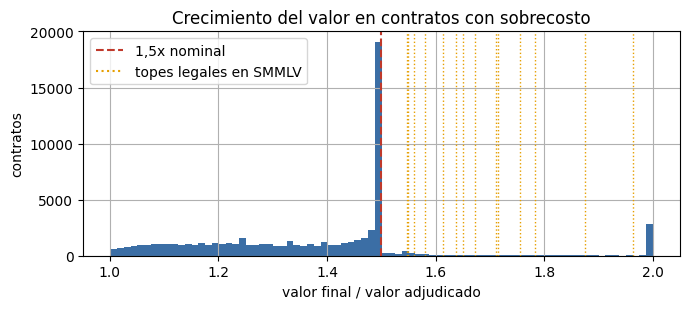

Escenario nominal : se descartan 5,600 registros -> quedan 242,573 | tasa de sobrecosto 24.9%
Escenario legal   : se descartan 3,655 registros -> quedan 244,518 | tasa de sobrecosto 25.5%

Contratos que el corte nominal descartaba y el legal conserva: 1,945 (crecimiento mediano 1.555)

Escenario principal: legal · 244,518 contratos · tasa 25.5%


,tasa,contratos
anio_firma,,
2021,0.239,50742
2022,0.260,60764
2023,0.264,64989
2024,0.255,68023


In [86]:
crecimiento = df.valor_final / df.valor_adjudicado
df["crecimiento"] = crecimiento
print(f"Tasa de sobrecosto antes del corte: {df.sobrecosto.mean():.1%}  ({df.sobrecosto.sum():,} de {len(df):,})")
print("\nCrecimiento (valor final / adjudicado) en contratos con sobrecosto:")
print(crecimiento[df.sobrecosto == 1].describe(percentiles=[.1, .5, .9, .99]).round(3))

# año de la última modificación (adiciones) para los contratos donde el tope importa
candidatos = df.loc[crecimiento > 1.5001, "id_contrato"]
mods = consulta_ids("adiciones_tope", ADICIONES, "id_contrato", candidatos, ["id_contrato", "tipo", "fecharegistro"])
tipo = mods.tipo.fillna("").str.lower()
mods = mods[tipo.str.contains("valor") | tipo.str.contains("modificacion general")]
anio_mod = pd.to_datetime(mods.fecharegistro, errors="coerce").dt.year.groupby(mods.id_contrato).max()

anio_ultima = df.id_contrato.map(anio_mod)
df["fuente_tope"] = np.where(anio_ultima.notna(), "adiciones", "fecha de fin")
anio_ultima = anio_ultima.fillna(df.fecha_fin.dt.year)
anio_ultima = np.maximum(anio_ultima.clip(upper=max(SMMLV)), df.anio_firma).astype(int)
df["tope_legal"] = 1 + 0.5 * anio_ultima.map(SMMLV) / df.anio_firma.map(SMMLV)
es_especial = df.modalidad_de_contratacion.str.contains("régimen especial", case=False, na=False)

print(f"\nContratos con crecimiento > 1,5x: {len(candidatos):,} · año tomado de adiciones: "
      f"{(df.loc[crecimiento > 1.5001, 'fuente_tope'] == 'adiciones').mean():.1%}, del resto: fecha de fin")

viola = {
    "nominal": np.asarray(crecimiento > 1.5001),
    "legal": np.where(es_especial, crecimiento > TOPE_ERROR, crecimiento > df.tope_legal + 1e-4),
}
fig, ax = plt.subplots(figsize=(7, 3.2))
crecimiento[df.sobrecosto == 1].clip(upper=2).hist(bins=80, ax=ax, color="#3b6ea5")
ax.axvline(1.5, color="#c0392b", ls="--", label="1,5x nominal")
for t in sorted(df.loc[crecimiento > 1.5001, "tope_legal"].round(3).unique()):
    if 1.5001 < t <= 2:
        ax.axvline(t, color="#e69f00", ls=":", lw=1)
ax.plot([], [], color="#e69f00", ls=":", label="topes legales en SMMLV")
ax.set(title="Crecimiento del valor en contratos con sobrecosto",
       xlabel="valor final / valor adjudicado", ylabel="contratos")
ax.legend(); plt.tight_layout(); plt.show()

ESCENARIOS = {}
for nombre, v in viola.items():
    d = df[~v].reset_index(drop=True)
    ESCENARIOS[nombre] = d
    print(f"Escenario {nombre:8s}: se descartan {int(v.sum()):,} registros -> quedan {len(d):,} "
          f"| tasa de sobrecosto {d.sobrecosto.mean():.1%}")

recuperados = (~viola["legal"]) & viola["nominal"]
print(f"\nContratos que el corte nominal descartaba y el legal conserva: {recuperados.sum():,} "
      f"(crecimiento mediano {crecimiento[recuperados].median():.3f})")

df = ESCENARIOS[CORTE_PRINCIPAL].copy()
EMBUDO[f"dentro del tope ({CORTE_PRINCIPAL})"] = len(df)
print(f"\nEscenario principal: {CORTE_PRINCIPAL} · {len(df):,} contratos · tasa {df.sobrecosto.mean():.1%}")
display(df.groupby("anio_firma").sobrecosto.agg(tasa="mean", contratos="size").round(3))

In [87]:
print("Tasa de sobrecosto por modalidad:")
display(df.groupby("modalidad_de_contratacion").sobrecosto.agg(tasa="mean", contratos="size")
          .sort_values("contratos", ascending=False).round(3))

Tasa de sobrecosto por modalidad:


,tasa,contratos
modalidad_de_contratacion,,
Mínima cuantía,0.202,140991
Contratación Directa (con ofertas),0.248,28924
Selección Abreviada de Menor Cuantía,0.394,25424
Selección abreviada subasta inversa,0.310,17190
Contratación régimen especial (con ofertas),0.258,17136
Concurso de méritos abierto,0.323,5681
Licitación pública,0.574,4916
Licitación pública Obra Publica,0.554,3605
Seleccion Abreviada Menor Cuantia Sin Manifestacion Interes,0.526,527


### 4.3 Validación del objetivo con el conjunto de adiciones

Si `valor_del_contrato` incluye las adiciones, los contratos marcados con sobrecosto deberían tener modificaciones registradas, y los demás casi nunca. Se toman 300 contratos de cada clase y se buscan sus registros en *SECOP II - Adiciones*.

Ese conjunto **no trae montos** y clasifica los registros de forma irregular: muchas adiciones de valor quedan como «Modificación general» o «No definido». Por eso la tabla muestra, para **cada tipo**, qué porcentaje de contratos de cada clase tiene al menos un registro. La lectura útil es la comparación entre clases: un tipo que aparece mucho más en los contratos con sobrecosto que en los demás está capturando adiciones.

In [88]:
muestra = pd.concat([df[df.sobrecosto == 1].sample(min(300, int(df.sobrecosto.sum())), random_state=SEMILLA),
                     df[df.sobrecosto == 0].sample(300, random_state=SEMILLA)])
adiciones = consulta_ids("adiciones_validacion", ADICIONES, "id_contrato", muestra.id_contrato.tolist())
print("Columnas de SECOP II - Adiciones:", adiciones.columns.tolist())

presencia = (pd.crosstab(adiciones.id_contrato, adiciones.tipo) > 0).reindex(muestra.id_contrato, fill_value=False)
presencia["valor o modificación general"] = presencia[[c for c in presencia.columns
                                                       if "valor" in c.lower() or "modificacion general" in c.lower()]].any(axis=1)
presencia["cualquier registro"] = presencia.any(axis=1)
por_clase = presencia.groupby(muestra.set_index("id_contrato").sobrecosto).mean().T
por_clase.columns = ["% sin sobrecosto", "% con sobrecosto"]
display((100 * por_clase).round(1).sort_values("% con sobrecosto", ascending=False))
print("Lectura: los tipos con un porcentaje alto en 'con sobrecosto' y bajo en 'sin sobrecosto' confirman la etiqueta.")

  adiciones_validacion: 595 llaves nuevas que no estaban guardadas; se descargan y se agregan
  cb9c-h8sn: 595 llaves consultadas -> 1,563 filas
Columnas de SECOP II - Adiciones: ['identificador', 'id_contrato', 'tipo', 'descripcion', 'fecharegistro']


,% sin sobrecosto,% con sobrecosto
tipo,,
cualquier registro,73.3,100.0
valor o modificación general,32.3,99.7
Modificacion General,31.3,85.3
No definido,49.7,57.3
Adicion en el valor,2.3,38.3
Conclusion,28.7,28.0
Suspensión,5.0,6.7
Reactivación,5.0,6.7
Cesion,0.3,0.7


Lectura: los tipos con un porcentaje alto en 'con sobrecosto' y bajo en 'sin sobrecosto' confirman la etiqueta.


### 4.4 Validación de `liquidaci_n` y de las demás cláusulas del contrato

Una columna que se fija **al firmar** debe tener una distribución parecida en contratos recién firmados y en los contratos del período. Una que se actualiza durante la ejecución, no: en los contratos nuevos todavía no ha cambiado. Se comparan ambas distribuciones con la **distancia de variación total** (0 = idénticas, 1 = sin nada en común). `estado_contrato` sirve de **control positivo**: se actualiza con seguridad, así que su distancia debe ser grande.

Regla: una cláusula con distancia mayor a 0,10 se trata como sospechosa y se excluye del modelo. Es una regla conservadora: una diferencia también puede venir de cambios en las prácticas de contratación entre años. La **dirección** ayuda a distinguirlas: si la cláusula se llenara al liquidar, los contratos viejos tendrían más «Si» que los nuevos.

In [89]:
CLAUSULAS = ["liquidaci_n", "obligaci_n_ambiental", "reversion", "el_contrato_puede_ser_prorrogado",
             "habilita_pago_adelantado", "documentos_tipo", "espostconflicto"]
desde = (FECHA_DESCARGA - pd.Timedelta(days=90)).strftime("%Y-%m-%d")
recientes = consulta("contratos_recientes", lambda: descargar(
    CONTRATOS, f"fecha_de_firma >= '{desde}' and modalidad_de_contratacion not in {SIN_OFERTAS}",
    CLAUSULAS + ["estado_contrato", "fecha_de_firma"], max_filas=20_000))

def variacion_total(a, b):
    pa = a.fillna("NA").value_counts(normalize=True)
    pb = b.fillna("NA").value_counts(normalize=True)
    return 0.5 * pa.subtract(pb, fill_value=0).abs().sum()

deriva = pd.DataFrame({
    "distancia": {c: variacion_total(df[c], recientes[c]) for c in CLAUSULAS + ["estado_contrato"]},
    "% 'Si' en el período": {c: (df[c] == "Si").mean() for c in CLAUSULAS},
    "% 'Si' recientes": {c: (recientes[c] == "Si").mean() for c in CLAUSULAS},
}).round(3)
display(deriva.sort_values("distancia", ascending=False))

if deriva.loc["estado_contrato", "distancia"] < 0.2:
    print("Aviso: el control positivo cambió poco; la prueba es poco informativa con esta muestra.")
EXCLUIR_POR_DERIVA = [c for c in CLAUSULAS if deriva.loc[c, "distancia"] > 0.10]
print(f"Cláusulas excluidas por sospecha de actualizarse después de firmar: {EXCLUIR_POR_DERIVA or 'ninguna'}")

print("\nTasa de sobrecosto según liquidaci_n:")
display(df.groupby("liquidaci_n").sobrecosto.agg(tasa="mean", contratos="size").round(3))
print("Distribución de liquidaci_n según estado_contrato (filas = estado):")
display(pd.crosstab(df.estado_contrato, df.liquidaci_n, normalize="index").round(3))

  contratos_recientes: 20,000 filas leídas de data/2026-10-20/


,distancia,% 'Si' en el período,% 'Si' recientes
estado_contrato,0.588,NaN,NaN
liquidaci_n,0.125,0.448,0.573
el_contrato_puede_ser_prorrogado,0.041,0.189,0.147
documentos_tipo,0.038,0.023,0.061
habilita_pago_adelantado,0.008,0.005,0.006
espostconflicto,0.004,0.006,0.001
obligaci_n_ambiental,0.003,0.041,0.045
reversion,0.000,0.000,0.000


Cláusulas excluidas por sospecha de actualizarse después de firmar: ['liquidaci_n']

Tasa de sobrecosto según liquidaci_n:


,tasa,contratos
liquidaci_n,,
No,0.232,135008
Si,0.284,109510


Distribución de liquidaci_n según estado_contrato (filas = estado):


liquidaci_n,No,Si
estado_contrato,,
Aprobado,0.774,0.226
Cerrado,0.547,0.453
En ejecución,0.648,0.352
Modificado,0.546,0.454
Suspendido,0.530,0.470
cedido,0.655,0.345
terminado,0.479,0.521


### 4.5 Las modalidades sin ofertas y la cobertura del modelo

*Contratación directa* y *Contratación régimen especial* sin ofertas son cerca del 90 % de los contratos del SECOP II. Quedan fuera por una razón **de datos** y, además, porque serían un problema distinto.

**Cómo funcionan.**

* **Contratación directa** (Ley 1150 de 2007, art. 2, num. 4): la entidad elige al contratista **sin concurso**, solo en causales que fija la ley, como servicios profesionales y de apoyo a la gestión, contratos interadministrativos, urgencia manifiesta, ausencia de pluralidad de oferentes o arrendamientos. En la muestra de abajo, más del 90 % son **prestación de servicios**, en su mayoría con personas naturales.
* **Régimen especial**: entidades que no se rigen por el Estatuto General de Contratación (Ley 80) sino por sus propios manuales, como hospitales públicos (ESE), empresas de servicios públicos, universidades públicas y empresas industriales y comerciales del Estado. En la variante «sin ofertas» también contratan de forma directa, y el tope de adiciones del artículo 40 de la Ley 80 no les aplica.

**Por qué no se puede calcular el sobrecosto.** El sobrecosto compara el **valor final** con el **valor inicial** del contrato:

1. El valor final sí está: `valor_del_contrato`, que SECOP II actualiza con cada adición (muestra el valor actual, no el original).
2. El valor inicial **no está de forma confiable**. Sin competencia no hay adjudicación, así que `valor_total_adjudicacion` es 0 en estas modalidades (la celda lo verifica: 0 % con valor adjudicado). El `precio_base` sí existe, pero es el presupuesto que la entidad estimó para el proceso, no el valor firmado, y no está validado que coincidan. El conjunto de *Adiciones* registra que hubo una modificación y cuándo, pero **no su monto**.

Sin valor inicial no hay etiqueta, y sin etiqueta no hay modelo: usar el precio base sin validarlo marcaría como sobrecosto diferencias que pueden ser solo de presupuestación.

**Además, sería otro problema.** Aun con el dato, convendría un modelo aparte: en la contratación directa las adiciones suelen ser prórrogas de contratos de servicios personales, un fenómeno distinto al de una compra u obra adjudicada por concurso; involucra datos de personas naturales; y son más de dos millones de contratos en el período.

Esta celda mide la falta de valor adjudicado con una muestra pseudoaleatoria (procesos cuya llave termina en `00`, cerca del 1 %) y calcula qué parte de los contratos del período cubre el modelo.

**Consecuencia para el proyecto:** el modelo responde la pregunta para las modalidades competitivas y las variantes «con ofertas». Extenderlo a la contratación directa exigiría validar primero que el precio base coincide con el valor inicial firmado (trabajo futuro).

In [90]:
conteo = consulta("conteo_modalidades", lambda: pd.DataFrame(_get(API.format(CONTRATOS).replace(".csv", ".json"), {
    "$select": "modalidad_de_contratacion, count(*) as contratos",
    "$where": f"fecha_de_firma between '{DESDE}' and '{HASTA}'",
    "$group": "modalidad_de_contratacion", "$order": "contratos DESC"}).json()).astype(str))
conteo["contratos"] = num(conteo["contratos"])
conteo["% del total"] = (100 * conteo.contratos / conteo.contratos.sum()).round(1)
print(f"Contratos firmados entre {min(ANIOS)} y {max(ANIOS)} por modalidad (todas):")
display(conteo)

es_sin_ofertas = conteo.modalidad_de_contratacion.isin(["Contratación directa", "Contratación régimen especial"])
COBERTURA = conteo.loc[~es_sin_ofertas, "contratos"].sum() / conteo.contratos.sum()
print(f"\n>>> El modelo cubre las modalidades que suman el {COBERTURA:.1%} de los contratos del período; "
      f"el {1 - COBERTURA:.1%} restante (sin ofertas) queda por fuera.")

so = consulta("muestra_sin_ofertas", lambda: descargar(
    CONTRATOS,
    f"fecha_de_firma between '{DESDE}' and '{HASTA}' "
    f"and modalidad_de_contratacion in {SIN_OFERTAS} and proceso_de_compra like '%00'",
    ["proceso_de_compra", "id_contrato", "modalidad_de_contratacion", "valor_del_contrato", "tipo_de_contrato"],
    max_filas=3_000))
proc_so = consulta_ids("procesos_sin_ofertas", PROCESOS, "id_del_portafolio", so.proceso_de_compra,
                       ["id_del_portafolio", "adjudicado", "valor_total_adjudicacion", "precio_base"])
proc_so = proc_so.drop_duplicates("id_del_portafolio", keep="last")
diag = so.merge(proc_so, left_on="proceso_de_compra", right_on="id_del_portafolio", how="left")
diag["tiene_proceso"] = diag.id_del_portafolio.notna()
diag["tiene_adjudicado"] = num(diag.valor_total_adjudicacion) > 0
diag["tiene_precio_base"] = num(diag.precio_base) > 0

resumen_so = diag.groupby("modalidad_de_contratacion").agg(
    contratos=("id_contrato", "size"), con_proceso=("tiene_proceso", "mean"),
    con_valor_adjudicado=("tiene_adjudicado", "mean"), con_precio_base=("tiene_precio_base", "mean"))
display(resumen_so.round(3))
print("Tipo de contrato en la muestra:")
display(so.tipo_de_contrato.value_counts(normalize=True).head(6).round(3))

  conteo_modalidades: 15 filas leídas de data/2026-10-20/
Contratos firmados entre 2021 y 2024 por modalidad (todas):


,modalidad_de_contratacion,contratos,% del total
0,Contratación directa,2325140,77.9
1,Contratación régimen especial,375787,12.6
2,Mínima cuantía,153170,5.1
3,Contratación Directa (con ofertas),32244,1.1
4,Selección Abreviada de Menor Cuantía,29112,1.0
5,Selección abreviada subasta inversa,24608,0.8
6,Contratación régimen especial (con ofertas),23386,0.8
7,Concurso de méritos abierto,7945,0.3
8,Licitación pública,7683,0.3
9,Licitación pública Obra Publica,4875,0.2



>>> El modelo cubre las modalidades que suman el 9.5% de los contratos del período; el 90.5% restante (sin ofertas) queda por fuera.
  muestra_sin_ofertas: 3,000 filas leídas de data/2026-10-20/
  procesos_sin_ofertas: 3 llaves nuevas que no estaban guardadas; se descargan y se agregan
  p6dx-8zbt: 3 llaves consultadas -> 0 filas


,contratos,con_proceso,con_valor_adjudicado,con_precio_base
modalidad_de_contratacion,,,,
Contratación directa,2625,0.999,0.0,0.990
Contratación régimen especial,375,1.000,0.0,0.997


Tipo de contrato en la muestra:


tipo_de_contrato
Prestación de servicios       0.917
Decreto 092 de 2017           0.035
Otro                          0.023
Arrendamiento de inmuebles    0.012
Suministros                   0.005
Obra                          0.004
Name: proportion, dtype: float64

## 5. Selección de variables: identificadores y fuga de información

### 5.1 Columnas excluidas

**Identificadores** (únicos por registro o por entidad/persona; no generalizan y permiten memorizar):
`id_contrato`, `referencia_del_contrato`, `proceso_de_compra`, `id_del_proceso`, `id_del_portafolio`, `referencia_del_proceso`, `id_adjudicacion`, `urlproceso`, `nit_entidad`, `codigo_entidad`, `nombre_entidad`, `documento_proveedor`, `codigo_proveedor`, `proveedor_adjudicado`, `nit_del_proveedor_adjudicado`, nombres y documentos de representante legal / supervisor / ordenadores, `c_digo_bpin`, datos bancarios.

**Fuga de información** (se conocen o se actualizan *después* de adjudicar):

| Columna | Por qué hay fuga |
|---|---|
| `valor_del_contrato` | incluye las adiciones: **es** el objetivo |
| `presupuesto_general_de_la_nacion_pgn`, `sistema_general_de_participaciones`, `sistema_general_de_regal_as`, `recursos_propios*`, `recursos_de_credito` | suman el valor **final** del contrato (se verifica abajo) |
| `fecha_de_fin_del_contrato`, `duraci_n_del_contrato` | se mueven con las prórrogas (se verifica abajo); `fecha_de_fin_del_contrato` solo se usa para filtrar contratos terminados (4.1) y como cota del tope legal (4.2) |
| `estado_contrato` | «Modificado» delata la adición |
| `dias_adicionados`, `fecha_de_notificaci_n_de_prorrogaci_n` | prórrogas posteriores |
| `valor_facturado`, `valor_pagado`, `valor_pendiente_*`, `valor_amortizado`, `saldo_cdp`, `saldo_vigencia` | ejecución financiera |
| `estado_del_procedimiento`, `estado_resumen`, `fase`, `ultima_actualizacion`, fechas de liquidación | estados posteriores |
| cláusulas en `EXCLUIR_POR_DERIVA` | cambian entre contratos nuevos y viejos (sección 4.4) |

**Texto libre** (`objeto_del_contrato`, `descripcion_del_proceso`): no se usa en este ejercicio. Un análisis previo mostró que el objeto y la descripción coinciden en la mayoría de los contratos, que el texto repite en buena parte la información de la categoría UNSPSC, que incluye siglas y programas propios de una sola entidad (así que funcionaría como un identificador de la entidad) y que algunos registros se editan después de firmar («se realizó otrosí»). Queda como trabajo futuro.

In [91]:
fuentes = sum(num(df[c]).fillna(0) for c in ["presupuesto_general_de_la_nacion_pgn", "recursos_propios"])
dur_fechas = (pd.to_datetime(df.fecha_de_fin_del_contrato, errors="coerce")
              - pd.to_datetime(df.fecha_de_inicio_del_contrato, errors="coerce")).dt.days

print("Sobrecosto según estado_contrato (fuga evidente):")
display(df.groupby("estado_contrato").sobrecosto.mean().round(3).to_frame("tasa de sobrecosto"))
print("Duración mediana según fechas del contrato (días):")
display(dur_fechas.groupby(df.sobrecosto).median().rename({0: "sin sobrecosto", 1: "con sobrecosto"}))
print(f"dias_adicionados > 0: tasa de sobrecosto {df.sobrecosto[num(df.dias_adicionados) > 0].mean():.1%} "
      f"vs {df.sobrecosto[~(num(df.dias_adicionados) > 0)].mean():.1%}")

Sobrecosto según estado_contrato (fuga evidente):


,tasa de sobrecosto
estado_contrato,
Aprobado,0.004
Cerrado,0.220
En ejecución,0.008
Modificado,0.578
Suspendido,0.254
cedido,0.069
terminado,0.285


Duración mediana según fechas del contrato (días):


sobrecosto
sin sobrecosto     66.0
con sobrecosto    202.0
dtype: float64

dias_adicionados > 0: tasa de sobrecosto 53.1% vs 22.1%


### 5.2 Variables del modelo (disponibles al adjudicar)

* **Entidad:** departamento, orden, sector, rama, centralizada/descentralizada.
* **Contrato y proceso:** tipo de contrato, modalidad, categoría UNSPSC (segmento y familia), origen de recursos, destino del gasto, cláusulas validadas en la sección 4.4, mes de firma.
* **Montos:** log del precio base, log del valor adjudicado y **descuento** (adjudicado / precio base).
* **Duración pactada** en días (del proceso, no de las fechas del contrato).
* **Competencia:** número de lotes, proveedores invitados, respuestas recibidas, proveedores únicos que respondieron.
* **Proveedor:** pyme, grupo/consorcio, tipo de documento.

In [92]:
CAT_CONTRATO = ["departamento", "orden", "sector", "rama", "entidad_centralizada", "tipo_de_contrato",
                "modalidad_de_contratacion", "origen_de_los_recursos", "destino_gasto", "es_pyme",
                "es_grupo", "tipodocproveedor"] + [c for c in CLAUSULAS if c not in EXCLUIR_POR_DERIVA]
CATEGORICAS = CAT_CONTRATO + ["unspsc_segmento", "unspsc_familia"]
NUMERICAS = ["log_precio_base", "log_valor_adjudicado", "adjudicado_sobre_base", "duracion_dias",
             "numero_de_lotes", "proveedores_invitados", "proveedores_con_invitacion",
             "respuestas_al_procedimiento", "proveedores_unicos_con", "mes_firma"]
DIAS = {"día(s)": 1, "Dia(s)": 1, "Semana(s)": 7, "Mes(es)": 30, "Año(s)": 365, "Hora(s)": 1 / 24}

def construir_X(d):
    X = d[CAT_CONTRATO].astype(str).copy()
    unspsc = d.codigo_de_categoria_principal.str.extract(r"V1\.(\d{8})")[0]
    X["unspsc_segmento"] = unspsc.str[:2].fillna("NA")
    X["unspsc_familia"] = unspsc.str[:4].fillna("NA")
    X["log_precio_base"] = np.log1p(d.precio_base_n)
    X["log_valor_adjudicado"] = np.log1p(d.valor_adjudicado)
    X["adjudicado_sobre_base"] = d.valor_adjudicado / d.precio_base_n
    X["duracion_dias"] = num(d.duracion) * d.unidad_de_duracion.map(DIAS)
    for c in ["numero_de_lotes", "proveedores_invitados", "proveedores_con_invitacion",
              "respuestas_al_procedimiento", "proveedores_unicos_con"]:
        X[c] = num(d[c])
    X["mes_firma"] = pd.to_datetime(d.fecha_de_firma, errors="coerce").dt.month
    return X[CATEGORICAS + NUMERICAS]

X = construir_X(df)
y = df.sobrecosto.values
grupos = df.nit_entidad.values   # solo para separar por entidad
print(X.shape, "·", len(CATEGORICAS), "categóricas ·", len(NUMERICAS), "numéricas")
X.head()

(244518, 30) · 20 categóricas · 10 numéricas


,departamento,orden,sector,rama,entidad_centralizada,tipo_de_contrato,modalidad_de_contratacion,origen_de_los_recursos,destino_gasto,es_pyme,es_grupo,tipodocproveedor,obligaci_n_ambiental,reversion,el_contrato_puede_ser_prorrogado,habilita_pago_adelantado,documentos_tipo,espostconflicto,unspsc_segmento,unspsc_familia,log_precio_base,log_valor_adjudicado,adjudicado_sobre_base,duracion_dias,numero_de_lotes,proveedores_invitados,proveedores_con_invitacion,respuestas_al_procedimiento,proveedores_unicos_con,mes_firma
0,Distrito Capital de Bogotá,Nacional,Cultura,Ejecutivo,Centralizada,Prestación de servicios,Mínima cuantía,Distribuido,Inversión,Si,No,NIT,No,No,No,No,No definido,No,72,7215,15.607270,15.607270,1.000000,210.0,0,0,0,2,2,4
1,Cesar,Territorial,Servicio Público,Ejecutivo,Descentralizada,Compraventa,Mínima cuantía,Distribuido,Funcionamiento,Si,No,NIT,No,No,No,No,No,No,43,4323,17.901235,17.891182,0.989997,10.0,0,0,0,0,0,12
2,No Definido,Territorial,agricultura,Corporación Autónoma,Centralizada,Decreto 092 de 2017,Contratación régimen especial (con ofertas),Recursos Propios,Inversión,Si,No,NIT,No,No,No,No,No,No,60,6010,19.257928,19.257928,1.000000,120.0,0,0,0,1,1,8
3,Tolima,Territorial,Servicio Público,Ejecutivo,Centralizada,Compraventa,Mínima cuantía,Distribuido,Funcionamiento,Si,No,NIT,No,No,No,No,No,No,95,9513,16.810993,16.808038,0.997049,3.0,0,0,0,3,3,12
4,Cundinamarca,Nacional,Ley de Justicia,Corporación Autónoma,Centralizada,Suministros,Mínima cuantía,Distribuido,Funcionamiento,Si,No,Cédula de Ciudadanía,No,No,No,No,No,No,82,8210,16.118096,16.118096,1.000000,270.0,0,0,0,5,5,3


### 5.3 Datos faltantes en las variables del modelo

Antes de decidir cómo tratar los faltantes hay que ver cuántos hay, dónde están y si dicen algo del sobrecosto. La tabla muestra, para cada variable del modelo:

* **% faltante** en entrenamiento (2021-2023) y en prueba (2024). En las categóricas cuenta como faltante el valor vacío (`NaN`, que `construir_X` convierte en el texto `"nan"`, o `"NA"` en UNSPSC) y, aparte, los **marcadores** que SECOP usa en lugar de un dato («No Definido» y similares).
* **Tasa de sobrecosto con y sin faltante**, solo en entrenamiento. Si difieren, el faltante es **informativo**: no ocurre al azar y conviene que el modelo lo vea.
* **Tratamiento actual** y una **sugerencia** según una regla simple:

| Situación | Sugerencia |
|---|---|
| sin faltantes | ninguno |
| más del 40 % faltante | evaluar excluir la variable (o usar solo un indicador de faltante) |
| el % faltante cambia 10 puntos o más entre entrenamiento y prueba | revisar la fuente: el registro cambió entre años |
| la tasa de sobrecosto difiere 5 puntos o más (con al menos 100 faltantes) | imputar **y** agregar un indicador de faltante |
| resto | imputación simple (mediana o categoría propia) |

La regla usa solo los faltantes; los marcadores ya funcionan como una categoría más, aunque conviene saber cuántos hay. La sugerencia es una guía para decidir; esta sección **no cambia** el tratamiento. Para agregar indicadores en los modelos lineales bastaría `SimpleImputer(strategy="median", add_indicator=True)` en `prep_lineal`; el boosting ya aprende una dirección propia para los faltantes en cada corte.

,tipo,% faltante entren.,% faltante prueba,% marcador entren.,n faltantes entren.,tasa con faltante,tasa sin faltante,tratamiento actual,Δ tasa (pp),sugerencia
variable,,,,,,,,,,
unspsc_segmento,categórica,3.55,10.09,0.00,6265,0.307,0.254,categoría propia «NA» (fuente: UNSPECIFIED),5.4,categoría propia (ya actúa como indicador)
unspsc_familia,categórica,3.55,10.09,0.00,6265,0.307,0.254,categoría propia «NA» (fuente: UNSPECIFIED),5.4,categoría propia (ya actúa como indicador)
documentos_tipo,categórica,0.00,0.00,4.86,0,NaN,0.255,categoría propia (one-hot / ordinal / nativa),NaN,ninguno
departamento,categórica,0.00,0.00,3.08,0,NaN,0.255,categoría propia (one-hot / ordinal / nativa),NaN,ninguno
habilita_pago_adelantado,categórica,0.00,0.00,2.32,0,NaN,0.255,categoría propia (one-hot / ordinal / nativa),NaN,ninguno
tipodocproveedor,categórica,0.00,0.00,1.22,0,NaN,0.255,categoría propia (one-hot / ordinal / nativa),NaN,ninguno
destino_gasto,categórica,0.00,0.00,0.17,0,NaN,0.255,categoría propia (one-hot / ordinal / nativa),NaN,ninguno
orden,categórica,0.00,0.00,0.00,0,NaN,0.255,categoría propia (one-hot / ordinal / nativa),NaN,ninguno
sector,categórica,0.00,0.00,0.00,0,NaN,0.255,categoría propia (one-hot / ordinal / nativa),NaN,ninguno


Variables con algún faltante: 3 de 30
Sugerencias: {'ninguno': 27, 'categoría propia (ya actúa como indicador)': 2, 'imputación simple': 1}


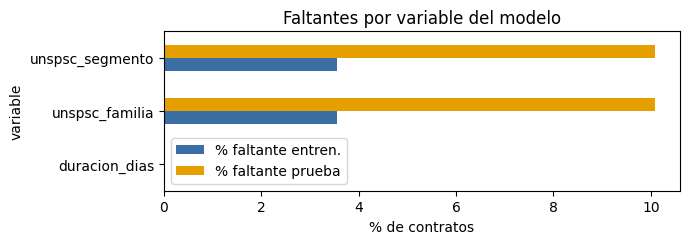

In [93]:
VACIO = {"", "nan", "none", "null", "na", "n/a"}
MARCADOR = {"no definido", "no definida", "sin definir", "no aplica", "sin descripcion", "sin descripción"}
anio = df.anio_firma.values
en_tr, en_te = np.isin(anio, ANIOS_ENTRENAMIENTO), anio == ANIO_PRUEBA

def pct(m):
    return 100 * m.mean() if len(m) else np.nan

filas = []
for c in CATEGORICAS + NUMERICAS:
    if c in CATEGORICAS:
        texto = X[c].astype(object).where(X[c].notna(), "nan").astype(str).str.strip().str.lower()   # NaN como texto en cualquier versión de pandas
        falta, marca = texto.isin(VACIO).values, texto.isin(MARCADOR).values
        actual = ("categoría propia «NA» (fuente: UNSPECIFIED)" if c.startswith("unspsc")
                  else "categoría propia (one-hot / ordinal / nativa)")
    else:
        v = X[c].astype(float)
        falta, marca = (~np.isfinite(v)).values, np.zeros(len(v), bool)
        actual = "mediana (lineal y árboles) · nativo (boosting)"
    ft = falta[en_tr]
    yt = y[en_tr]
    filas.append({"variable": c, "tipo": "categórica" if c in CATEGORICAS else "numérica",
                  "% faltante entren.": pct(ft), "% faltante prueba": pct(falta[en_te]),
                  "% marcador entren.": pct(marca[en_tr]) if c in CATEGORICAS else np.nan,
                  "n faltantes entren.": int(ft.sum()),
                  "tasa con faltante": yt[ft].mean() if ft.any() else np.nan,
                  "tasa sin faltante": yt[~ft].mean() if (~ft).any() else np.nan,
                  "tratamiento actual": actual})
faltantes = pd.DataFrame(filas).set_index("variable")
faltantes["Δ tasa (pp)"] = 100 * (faltantes["tasa con faltante"] - faltantes["tasa sin faltante"])

def sugerencia(r):
    p = max(r["% faltante entren."], r["% faltante prueba"])
    cat = r["tipo"] == "categórica"
    if p == 0:
        return "ninguno"
    if p > 40:
        return "evaluar excluir (o solo indicador)"
    if abs(r["% faltante prueba"] - r["% faltante entren."]) >= 10:
        return "revisar fuente: cambia entre años"
    if abs(r["Δ tasa (pp)"]) >= 5 and r["n faltantes entren."] >= 100:
        # en una categórica, la categoría propia ya es el indicador de faltante
        return "categoría propia (ya actúa como indicador)" if cat else "imputar + indicador de faltante"
    return "categoría propia" if cat else "imputación simple"

faltantes["sugerencia"] = faltantes.apply(sugerencia, axis=1)
faltantes = faltantes.sort_values(["% faltante entren.", "% marcador entren."], ascending=False)
display(faltantes.round({"% faltante entren.": 2, "% faltante prueba": 2, "% marcador entren.": 2,
                         "tasa con faltante": 3, "tasa sin faltante": 3, "Δ tasa (pp)": 1}))

con_falta = faltantes[(faltantes["% faltante entren."] > 0) | (faltantes["% faltante prueba"] > 0)]
print(f"Variables con algún faltante: {len(con_falta)} de {len(faltantes)}")
print("Sugerencias:", faltantes.sugerencia.value_counts().to_dict())
if len(con_falta):
    ax = con_falta[["% faltante entren.", "% faltante prueba"]].iloc[::-1].plot.barh(
        figsize=(7, 0.35 * len(con_falta) + 1.5), color=["#3b6ea5", "#e69f00"])
    ax.set(xlabel="% de contratos", title="Faltantes por variable del modelo")
    plt.tight_layout(); plt.show()

#### Nota sobre UNSPSC: el valor `UNSPECIFIED`

La tabla muestra que `unspsc_segmento` y `unspsc_familia` tienen 3,6 % de faltantes en entrenamiento y 10,1 % en prueba. **No es un error del cuaderno ni de la descarga.**

* **Qué es UNSPSC.** Es el clasificador de bienes y servicios de Naciones Unidas que usa Colombia Compra Eficiente. El código de 8 dígitos (por ejemplo `V1.80111600`) dice qué se compra; el **segmento** (2 primeros dígitos) y la **familia** (4 primeros) agrupan productos parecidos. La familia es la variable más importante del modelo (sección 11).
* **De dónde sale el faltante.** Cuando la entidad no clasifica el contrato, SECOP II no deja el campo vacío: registra el texto `UNSPECIFIED`. Ese texto no tiene el formato del código, así que queda sin segmento ni familia. La verificación de abajo muestra que casi no aparece en 2021-2022 (menos del 1 %) y sube a 8,3 % en 2023 y a 10,1 % en 2024. El 3,6 % de entrenamiento es el promedio de 2021-2023.
* **Qué significa.** Es un **cambio en la forma de registrar** los contratos desde 2023, no una pérdida de datos en el proceso. Los contratos sin categoría tienen más sobrecosto (30,8 % frente a 25,3 % en entrenamiento): no ocurren al azar.
* **Cómo se trata.** `construir_X` los deja en una **categoría propia** (`"NA"`). En una variable categórica, esa categoría **es** el indicador de faltante: el modelo aprende la tasa propia de esos contratos sin inventarles un tipo de bien. Imputarlos con la categoría más frecuente sería peor: asignaría un tipo de bien falso a uno de cada diez contratos de 2024.
* **Por qué no compromete los resultados.** El entrenamiento incluye 2023, así que el modelo ve más de 6.000 contratos `UNSPECIFIED`. La segunda ventana temporal (sección 12.2) entrena con 2021-2022, casi sin ellos, y evalúa en 2023, donde ya son el 8 %: su PR-AUC (0,566) no es menor que la de la ventana principal.
* **Riesgo que queda.** Si la proporción sigue creciendo, la variable más importante pierde información para una parte mayor de los contratos. Por eso se reevalúa el modelo cada año (limitación 6).

In [94]:
# de dónde vienen los faltantes numéricos: valores que no se pudieron leer y unidades de duración sin equivalencia
fuente = {"duracion_dias": "duracion", "numero_de_lotes": "numero_de_lotes",
          "proveedores_invitados": "proveedores_invitados", "proveedores_con_invitacion": "proveedores_con_invitacion",
          "respuestas_al_procedimiento": "respuestas_al_procedimiento", "proveedores_unicos_con": "proveedores_unicos_con",
          "mes_firma": "fecha_de_firma"}
origen = pd.DataFrame({v: {"vacío en la fuente": int(df[col].isna().sum()),
                           "no interpretable": int((df[col].notna() & (num(df[col]) if v != "mes_firma"
                                                   else pd.to_datetime(df[col], errors="coerce")).isna()).sum())}
                       for v, col in fuente.items()}).T
sin_unidad = ~df.unidad_de_duracion.isin(list(DIAS))
origen.loc["duracion_dias", "unidad sin equivalencia"] = int(sin_unidad.sum())
display(origen.fillna(0).astype(int))
if sin_unidad.any():
    print("Unidades de duración que no están en DIAS:", df.unidad_de_duracion[sin_unidad].value_counts(dropna=False).head(10).to_dict())

,vacío en la fuente,no interpretable,unidad sin equivalencia
duracion_dias,0,0,3
numero_de_lotes,0,0,0
proveedores_invitados,0,0,0
proveedores_con_invitacion,0,0,0
respuestas_al_procedimiento,0,0,0
proveedores_unicos_con,0,0,0
mes_firma,0,0,0


Unidades de duración que no están en DIAS: {'No Especificado': 3}


#### Verificaciones puntuales

**UNSPSC sin código.** Confirma lo explicado en la nota anterior: cuántos contratos quedan sin código por año, qué texto trae la fuente en esos casos y su tasa de sobrecosto.

**Duración del proceso.** *Procesos* es una foto del estado actual del proceso, no su historial. Si las entidades actualizaran la duración del proceso al prorrogar el contrato, `duracion_dias` tendría fuga. Se compara con la duración final del contrato (por fechas, que sí incluye prórrogas): si la variable es la duración **pactada**, en los contratos con sobrecosto (que suelen prorrogarse) debe coincidir menos con la final y la razón pactada/final debe ser menor que 1.

In [95]:
cod = df.codigo_de_categoria_principal
no_leido = cod.str.extract(r"V1\.(\d{8})")[0].isna()
print("UNSPSC sin código por año de firma:")
SIN_UNSPSC = no_leido.groupby(df.anio_firma).mean().rename("proporcion")
display(SIN_UNSPSC.round(3).to_frame("% sin código"))
print("Valores sin código en la fuente:", cod[no_leido].value_counts(dropna=False).head(5).to_dict())
ap_unspsc = df.sobrecosto[no_leido & en_tr].mean(), df.sobrecosto[~no_leido & en_tr].mean()
print(f"Tasa de sobrecosto en entrenamiento: sin código {ap_unspsc[0]:.3f} · con código {ap_unspsc[1]:.3f}")

igual = (X.duracion_dias - dur_fechas).abs() <= 5
razon = X.duracion_dias / dur_fechas.replace(0, np.nan)
chequeo_dur = pd.DataFrame({"duración pactada ≈ final (±5 días)": igual.groupby(df.sobrecosto).mean(),
                            "mediana pactada / final": razon.groupby(df.sobrecosto).median()}
                           ).rename(index={0: "sin sobrecosto", 1: "con sobrecosto"}).round(3)
display(chequeo_dur)
sin_fuga = (chequeo_dur.iloc[1, 0] < chequeo_dur.iloc[0, 0]) and (chequeo_dur.iloc[1, 1] < 1)
print("duracion_dias:", "se comporta como duración pactada (sin evidencia de fuga)" if sin_fuga
      else "ADVERTENCIA: coincide con la duración final también en contratos con sobrecosto; revisar fuga")

UNSPSC sin código por año de firma:


,% sin código
anio_firma,
2021,0.007
2022,0.008
2023,0.083
2024,0.101


Valores sin código en la fuente: {'UNSPECIFIED': 13130}
Tasa de sobrecosto en entrenamiento: sin código 0.307 · con código 0.254


,duración pactada ≈ final (±5 días),mediana pactada / final
sobrecosto,,
sin sobrecosto,0.44,1.000
con sobrecosto,0.20,0.774


duracion_dias: se comporta como duración pactada (sin evidencia de fuga)


## 6. Partición temporal y validación cruzada agrupada por entidad

* **Entrenamiento:** contratos firmados entre 2021 y 2023 (`ANIOS_ENTRENAMIENTO`).
* **Prueba:** contratos firmados en 2024 (`ANIO_PRUEBA`). Simula el uso real: el modelo se construye con el pasado y se aplica a contratos nuevos. Se usa **una sola vez**, en la sección 10. Incluye entidades que ya contrataban antes y entidades nuevas; la sección 10 reporta ambas por separado.
* **Validación cruzada** dentro de entrenamiento (`GroupKFold`, `N_PLIEGUES` pliegues, **por entidad**): elige hiperparámetros, el número de iteraciones del boosting, las épocas de la red y el **umbral** de cada modelo, con predicciones fuera de pliegue. Una misma entidad contrata de forma parecida; si sus contratos quedaran a ambos lados de un pliegue, el modelo la «reconocería» y la validación sería optimista.

La parada temprana interna de `HistGradientBoostingClassifier` y de `MLPClassifier` separa la validación **por filas**, mezclando contratos de una misma entidad. Por eso se desactiva y el número de iteraciones o épocas se elige con estos mismos pliegues por entidad.

In [96]:
anios = df.anio_firma.values
tr = np.where(np.isin(anios, ANIOS_ENTRENAMIENTO))[0]
te = np.where(anios == ANIO_PRUEBA)[0]
X_tr, X_te, y_tr, y_te = X.iloc[tr], X.iloc[te], y[tr], y[te]
g_tr, g_te = grupos[tr], grupos[te]
ENTIDAD_NUEVA = ~np.isin(g_te, g_tr)      # entidades de prueba que no aparecen en entrenamiento
print(f"Entrenamiento {ANIOS_ENTRENAMIENTO}: {len(tr):,} contratos, {len(set(g_tr)):,} entidades | tasa {y_tr.mean():.1%}")
print(f"Prueba {ANIO_PRUEBA}:            {len(te):,} contratos, {len(set(g_te)):,} entidades | tasa {y_te.mean():.1%}")
print(f"  de la prueba, contratos de entidades nuevas: {ENTIDAD_NUEVA.sum():,} ({ENTIDAD_NUEVA.mean():.1%})")

PLIEGUES = list(GroupKFold(n_splits=N_PLIEGUES).split(X_tr, y_tr, g_tr))
for k, (a, v) in enumerate(PLIEGUES, 1):
    assert not set(g_tr[a]) & set(g_tr[v])
    print(f"  pliegue {k}: validación {len(v):,} contratos, {len(set(g_tr[v])):,} entidades, tasa {y_tr[v].mean():.1%}")

Entrenamiento [2021, 2022, 2023]: 176,495 contratos, 2,542 entidades | tasa 25.5%
Prueba 2024:            68,023 contratos, 2,318 entidades | tasa 25.5%
  de la prueba, contratos de entidades nuevas: 1,896 (2.8%)
  pliegue 1: validación 35,299 contratos, 499 entidades, tasa 24.5%
  pliegue 2: validación 35,299 contratos, 510 entidades, tasa 26.9%
  pliegue 3: validación 35,299 contratos, 511 entidades, tasa 25.3%
  pliegue 4: validación 35,299 contratos, 511 entidades, tasa 24.3%
  pliegue 5: validación 35,299 contratos, 511 entidades, tasa 26.8%


## 7. Marco de evaluación

**Métrica para elegir modelos e hiperparámetros:** PR-AUC (precisión promedio), media de los pliegues por entidad. Con 25 % de positivos, un clasificador al azar tiene PR-AUC igual a la tasa de positivos; el ROC-AUC se reporta como complemento.

**Regla del umbral (igual para todos los modelos):** el umbral que maximiza **F-beta** en las predicciones **fuera de pliegue** del entrenamiento. Con `BETA = 1` es el F1; con `BETA = 2`, la exhaustividad pesa el doble, útil si a una contraloría le cuesta más dejar pasar un sobrecosto que revisar un contrato de más. El umbral nunca se elige con la prueba ni con predicciones del propio entrenamiento.

**Incertidumbre:** bootstrap **por entidad** sobre la prueba (contratos de 2024): se remuestrean entidades completas, no filas, porque los contratos de una entidad no son independientes.

**Preprocesamiento** (ajustado siempre dentro de cada pliegue):

* *lineal* (logística y red): one-hot de categorías con al menos 30 casos, mediana para faltantes y estandarización.
* *árboles* (árbol y bosque): códigos ordinales de categoría y mediana para faltantes; los árboles no necesitan escalar.
* *boosting*: categorías nativas de `HistGradientBoostingClassifier`.

In [97]:
prep_lineal = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=30), CATEGORICAS),
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("esc", StandardScaler())]), NUMERICAS),
])
prep_arbol = ColumnTransformer([
    ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1,
                           encoded_missing_value=-2), CATEGORICAS),
    ("num", SimpleImputer(strategy="median"), NUMERICAS),
])

# niveles para el boosting, aprendidos SOLO en entrenamiento (máx. 250 por columna); lo demás -> "OTRA"
NIVELES = {c: X_tr[c].value_counts().index[:250].tolist() for c in CATEGORICAS}
def a_categorias(D):
    D = D.copy()
    for c in CATEGORICAS:
        D[c] = pd.Categorical(D[c].where(D[c].isin(NIVELES[c]), "OTRA"), categories=NIVELES[c] + ["OTRA"])
    return D
Xc_tr, Xc_te = a_categorias(X_tr), a_categorias(X_te)


def fuera_de_pliegue(estimador, Xd, yd, pliegues=PLIEGUES):
    """Predicciones fuera de pliegue y PR-AUC de cada pliegue."""
    p = np.full(len(yd), np.nan)
    ap = []
    for a, v in pliegues:
        m = clone(estimador).fit(Xd.iloc[a], yd[a])
        p[v] = m.predict_proba(Xd.iloc[v])[:, 1]
        ap.append(average_precision_score(yd[v], p[v]))
    return p, np.array(ap)


BUSQUEDAS = {}   # tablas de búsqueda de hiperparámetros de cada modelo (se guardan con la corrida)

def buscar(estimador, grilla, clave, Xd=None, yd=None, regla="mejor"):
    """Prueba cada combinación con los pliegues por entidad.
    regla='mejor': mayor PR-AUC media; regla='1EE': la más simple (última de la grilla) dentro de un error estándar."""
    Xd = X_tr if Xd is None else Xd
    yd = y_tr if yd is None else yd
    filas, oofs = [], []
    for params in grilla:
        p, ap = fuera_de_pliegue(clone(estimador).set_params(**params), Xd, yd)
        filas.append({**{k.split("__")[-1]: v for k, v in params.items()},
                      "PR-AUC media": ap.mean(), "error estándar": ap.std(ddof=1) / np.sqrt(len(ap))})
        oofs.append(p)
    tabla = pd.DataFrame(filas)
    i_mejor = int(tabla["PR-AUC media"].idxmax())
    if regla == "1EE":
        piso = tabla.loc[i_mejor, "PR-AUC media"] - tabla.loc[i_mejor, "error estándar"]
        i_mejor = int(tabla.index[tabla["PR-AUC media"] >= piso].max())
    tabla["elegido"] = np.where(tabla.index == i_mejor, "◀", "")
    BUSQUEDAS[clave] = tabla
    mostrar_busqueda(clave)
    return grilla[i_mejor], oofs[i_mejor]


def mostrar_busqueda(clave):
    display(BUSQUEDAS[clave].round({"PR-AUC media": 4, "error estándar": 4}))


def elegir_umbral(yd, p, beta=BETA):
    prec, rec, umb = precision_recall_curve(yd, p)
    fb = (1 + beta**2) * prec[:-1] * rec[:-1] / (beta**2 * prec[:-1] + rec[:-1] + 1e-12)
    return float(umb[np.nanargmax(fb)])


# ---------------- corrida: guardar o cargar ----------------
MODELOS = {}      # nombre -> dict(p_oof, p_te, umbral, predictor, X_prueba, ajustar)
# `ajustar(Xa, ya)` reentrena el modelo con los hiperparámetros ya elegidos sobre otros datos (sin convertir);
# lo usan la curva de aprendizaje, la robustez y el modelo final de la sección 14, sea cual sea el campeón.
RESULTADOS = {}   # todo lo que se guarda de la corrida en corridas/<corrida>/resultados.joblib

def guardar_resultados():
    """Guarda lo calculado hasta ahora (solo cuando se entrena)."""
    if ENTRENAR_MODELOS:
        RESULTADOS["modelos"] = {n: {k: m[k] for k in ("p_oof", "p_te", "umbral")} for n, m in MODELOS.items()}
        RESULTADOS["busquedas"] = BUSQUEDAS
        joblib.dump(RESULTADOS, DIR_CORRIDA / "resultados.joblib", compress=3)

def nota(clave, texto=None):
    """Imprime un resultado de texto; al entrenar lo guarda, al cargar lo recupera."""
    if ENTRENAR_MODELOS:
        RESULTADOS.setdefault("notas", {})[clave] = texto
    print(RESULTADOS["notas"][clave])

if ENTRENAR_MODELOS:
    RESULTADOS.update(id_tr=df.id_contrato.values[tr], id_te=df.id_contrato.values[te])
else:
    RESULTADOS = joblib.load(DIR_CORRIDA / "resultados.joblib")
    if not (np.array_equal(RESULTADOS["id_tr"], df.id_contrato.values[tr])
            and np.array_equal(RESULTADOS["id_te"], df.id_contrato.values[te])):
        raise ValueError("Los contratos no coinciden con los de la corrida cargada: revise DATOS y los parámetros.")
    BUSQUEDAS = RESULTADOS["busquedas"]
    print(f"Corrida {DIR_CORRIDA.name} cargada · modelos: {list(RESULTADOS['modelos'])}")

def registrar(nombre, p_oof=None, p_te=None, predictor=None, X_prueba=None, ajustar=None, umbral=None):
    if ENTRENAR_MODELOS:
        u = elegir_umbral(y_tr, p_oof) if umbral is None else umbral
        MODELOS[nombre] = dict(p_oof=p_oof, p_te=p_te, umbral=u, predictor=predictor, X_prueba=X_prueba, ajustar=ajustar)
        guardar_resultados()
    else:
        MODELOS[nombre] = dict(RESULTADOS["modelos"][nombre], predictor=None, X_prueba=None, ajustar=None)
    m = MODELOS[nombre]
    print(f"{nombre}: PR-AUC fuera de pliegue {average_precision_score(y_tr, m['p_oof']):.4f} · umbral F{BETA:g} = {m['umbral']:.3f}"
          + ("" if ENTRENAR_MODELOS else "  (cargado)"))

Corrida 2026-10-21_1326 cargada · modelos: ['Línea base', 'Regresión logística', 'Árbol de decisión', 'Bosque aleatorio', 'Gradient Boosting', 'Red neuronal']


## 8. Modelos

Con `ENTRENAR_MODELOS = False`, las celdas de esta sección y de la 9 no entrenan: muestran las tablas de búsqueda y las predicciones guardadas en la corrida.

### 8.1 Línea base y regresión logística

La logística se ajusta con `class_weight="balanced"`, así que sus probabilidades **no** están calibradas (se reparten como si las clases fueran 50/50). Eso no afecta el orden (ROC-AUC, PR-AUC), pero hace que su umbral natural no sea 0,5: por eso su umbral también se elige con la regla F-beta fuera de pliegue. Se busca la fuerza de regularización `C`.

**Estandarización:** la logística va dentro de un `Pipeline` cuyo primer paso es `prep_lineal` (sección 7). Ese paso imputa con la mediana y **estandariza** las variables numéricas con `StandardScaler` (resta la media y divide por la desviación estándar), y convierte las categóricas a one-hot (0/1, sin escalar). Como es parte del pipeline, la media y la desviación se calculan solo con los datos de entrenamiento de cada pliegue y luego se aplican a la validación y a la prueba, sin filtrar información. Sin estandarizar, la penalización `C` castigaría distinto a cada variable según sus unidades y los coeficientes no serían comparables. La red neuronal (sección 9) usa el mismo `prep_lineal`.

In [98]:
base = DummyClassifier(strategy="prior")
logit = Pipeline([("prep", prep_lineal),
                  ("clf", LogisticRegression(max_iter=3000, class_weight="balanced"))])
if ENTRENAR_MODELOS:
    p_oof_base, _ = fuera_de_pliegue(base, X_tr, y_tr)
    base_final = clone(base).fit(X_tr, y_tr)
    registrar("Línea base", p_oof_base, base_final.predict_proba(X_te)[:, 1], base_final, X_te,
              ajustar=lambda Xa, ya: clone(base).fit(Xa, ya), umbral=1.0)
    params_logit, oof_logit = buscar(logit, [{"clf__C": c} for c in [0.01, 0.1, 1.0]], "logit")
    logit_final = clone(logit).set_params(**params_logit).fit(X_tr, y_tr)
    registrar("Regresión logística", oof_logit, logit_final.predict_proba(X_te)[:, 1], logit_final, X_te,
              ajustar=lambda Xa, ya: clone(logit).set_params(**params_logit).fit(Xa, ya))
else:
    mostrar_busqueda("logit")
    registrar("Línea base"); registrar("Regresión logística")

,C,PR-AUC media,error estándar,elegido
0,0.01,0.5037,0.0156,
1,0.10,0.5045,0.0152,◀
2,1.00,0.5042,0.0151,


Línea base: PR-AUC fuera de pliegue 0.2483 · umbral F1 = 1.000  (cargado)
Regresión logística: PR-AUC fuera de pliegue 0.5040 · umbral F1 = 0.477  (cargado)


### 8.2 Árbol de decisión

Se poda con `ccp_alpha` y la **regla de un error estándar**: entre los valores cuya PR-AUC media queda a menos de un error estándar (desviación entre pliegues dividida por √k) del mejor, se elige el más podado. `min_samples_leaf = 50` evita hojas con probabilidades inestables.

In [99]:
arbol = Pipeline([("prep", prep_arbol),
                  ("clf", DecisionTreeClassifier(min_samples_leaf=50, random_state=SEMILLA))])
ALFAS = [0.0, 2e-5, 5e-5, 1e-4, 2e-4, 5e-4, 1e-3]
if ENTRENAR_MODELOS:
    params_arbol, oof_arbol = buscar(arbol, [{"clf__ccp_alpha": a} for a in ALFAS], "arbol", regla="1EE")
    arbol_final = clone(arbol).set_params(**params_arbol).fit(X_tr, y_tr)
    nota("arbol", f"Árbol final: {arbol_final[-1].get_n_leaves()} hojas, profundidad {arbol_final[-1].get_depth()}")
    registrar("Árbol de decisión", oof_arbol, arbol_final.predict_proba(X_te)[:, 1], arbol_final, X_te,
              ajustar=lambda Xa, ya: clone(arbol).set_params(**params_arbol).fit(Xa, ya))
else:
    mostrar_busqueda("arbol"); nota("arbol")
    registrar("Árbol de decisión")

,ccp_alpha,PR-AUC media,error estándar,elegido
0,0.00000,0.4681,0.0164,
1,0.00002,0.4779,0.0169,
2,0.00005,0.4805,0.0167,
3,0.00010,0.4752,0.0166,◀
4,0.00020,0.4610,0.0146,
5,0.00050,0.4361,0.0116,
6,0.00100,0.4177,0.0110,


Árbol final: 86 hojas, profundidad 11
Árbol de decisión: PR-AUC fuera de pliegue 0.4782 · umbral F1 = 0.261  (cargado)


### 8.3 Bosque aleatorio

Cada árbol ve una muestra bootstrap de filas y, en cada corte, un subconjunto de variables (`max_features`). El error *out-of-bag* **no** se usa: las filas fuera de bolsa comparten entidad con las de dentro, así que sería optimista; se usa la misma validación cruzada por entidad.

In [100]:
bosque = Pipeline([("prep", prep_arbol),
                   ("clf", RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEMILLA))])
grilla_bosque = [{"clf__max_features": mf, "clf__min_samples_leaf": hoja}
                 for mf in ["sqrt", 0.3] for hoja in [5, 20]]
if ENTRENAR_MODELOS:
    params_bosque, oof_bosque = buscar(bosque, grilla_bosque, "bosque")
    bosque_final = clone(bosque).set_params(**params_bosque, clf__n_estimators=400).fit(X_tr, y_tr)
    registrar("Bosque aleatorio", oof_bosque, bosque_final.predict_proba(X_te)[:, 1], bosque_final, X_te,
              ajustar=lambda Xa, ya: clone(bosque).set_params(**params_bosque, clf__n_estimators=400).fit(Xa, ya))
else:
    mostrar_busqueda("bosque")
    registrar("Bosque aleatorio")

,max_features,min_samples_leaf,PR-AUC media,error estándar,elegido
0,sqrt,5,0.5371,0.0175,◀
1,sqrt,20,0.5328,0.0170,
2,0.3,5,0.5347,0.0172,
3,0.3,20,0.5338,0.0173,


Bosque aleatorio: PR-AUC fuera de pliegue 0.5373 · umbral F1 = 0.273  (cargado)


### 8.4 Gradient Boosting

Se desactiva la parada temprana interna y, para cada combinación, se entrena hasta `ITER_MAX` iteraciones en cada pliegue, midiendo la PR-AUC de validación cada `PASO` iteraciones con `staged_predict_proba`. Se elige la combinación y el número de iteraciones con mejor PR-AUC media, y el modelo final se reentrena con todo el entrenamiento y ese número fijo de iteraciones.

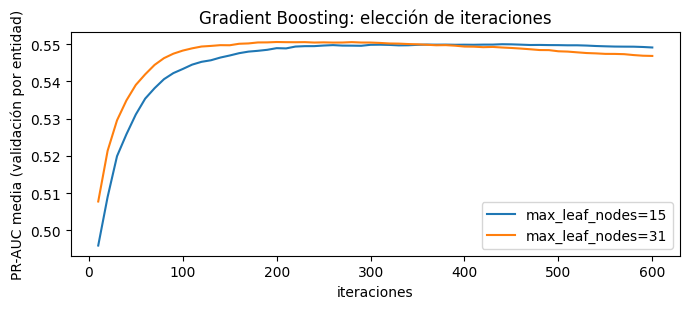

,max_leaf_nodes,iteraciones,PR-AUC media,error estándar
0,15,440,0.5500,0.0150
1,31,200,0.5506,0.0147


Gradient Boosting: PR-AUC fuera de pliegue 0.5509 · umbral F1 = 0.263  (cargado)


In [101]:
ITER_MAX, PASO = 600, 10
gb_base = dict(learning_rate=0.06, l2_regularization=1.0, categorical_features="from_dtype",
               early_stopping=False, random_state=SEMILLA)


class BoostingConCategorias(ClassifierMixin, BaseEstimator):
    """Boosting que aprende los niveles de categoría en sus propios datos de ajuste y recibe X sin convertir."""
    def __init__(self, hojas=31, iters=100):
        self.hojas, self.iters = hojas, iters
    def fit(self, Xa, ya):
        self.classes_ = np.array([0, 1])
        self.niveles = {c: Xa[c].value_counts().index[:250].tolist() for c in CATEGORICAS}
        self.modelo = HistGradientBoostingClassifier(max_iter=self.iters, max_leaf_nodes=self.hojas, **gb_base)
        self.modelo.fit(self._conv(Xa), ya)
        return self
    def _conv(self, D):
        return D.assign(**{c: pd.Categorical(D[c].where(D[c].isin(self.niveles[c]), "OTRA"),
                                             categories=self.niveles[c] + ["OTRA"]) for c in CATEGORICAS})
    def predict_proba(self, D):
        return self.modelo.predict_proba(self._conv(D))


def curva_gb(max_leaf_nodes):
    curvas, staged = [], []
    for a, v in PLIEGUES:
        m = HistGradientBoostingClassifier(max_iter=ITER_MAX, max_leaf_nodes=max_leaf_nodes, **gb_base)
        m.fit(Xc_tr.iloc[a], y_tr[a])
        ps = [pr[:, 1] for k, pr in enumerate(m.staged_predict_proba(Xc_tr.iloc[v]), 1) if k % PASO == 0]
        curvas.append([average_precision_score(y_tr[v], p) for p in ps])
        staged.append(ps)
    return np.array(curvas), staged

if ENTRENAR_MODELOS:
    filas, mejor, CURVAS_GB = [], None, {}
    for hojas in [15, 31]:
        curvas, staged = curva_gb(hojas)
        media = curvas.mean(axis=0)
        i = int(np.argmax(media))
        iters = (np.arange(len(media)) + 1) * PASO
        CURVAS_GB[hojas] = media
        filas.append({"max_leaf_nodes": hojas, "iteraciones": int(iters[i]), "PR-AUC media": media[i],
                      "error estándar": curvas[:, i].std(ddof=1) / np.sqrt(len(PLIEGUES))})
        if mejor is None or media[i] > mejor["ap"]:
            oof = np.full(len(y_tr), np.nan)
            for (a, v), ps in zip(PLIEGUES, staged):
                oof[v] = ps[i]
            mejor = dict(ap=media[i], hojas=hojas, iters=int(iters[i]), oof=oof)
    BUSQUEDAS["gb"] = pd.DataFrame(filas)
    RESULTADOS["curvas_gb"] = CURVAS_GB
    RESULTADOS["gb"] = {k: mejor[k] for k in ("hojas", "iters")}
else:
    CURVAS_GB, mejor = RESULTADOS["curvas_gb"], dict(RESULTADOS["gb"])

fig, ax = plt.subplots(figsize=(7, 3.2))
for hojas, media in CURVAS_GB.items():
    ax.plot((np.arange(len(media)) + 1) * PASO, media, label=f"max_leaf_nodes={hojas}")
ax.set(xlabel="iteraciones", ylabel="PR-AUC media (validación por entidad)", title="Gradient Boosting: elección de iteraciones")
ax.legend(); plt.tight_layout(); plt.show()
mostrar_busqueda("gb")

if ENTRENAR_MODELOS:
    gb = HistGradientBoostingClassifier(max_iter=mejor["iters"], max_leaf_nodes=mejor["hojas"], **gb_base).fit(Xc_tr, y_tr)
    p_gb = gb.predict_proba(Xc_te)[:, 1]
    registrar("Gradient Boosting", mejor["oof"], p_gb, gb, Xc_te,
              ajustar=lambda Xa, ya: BoostingConCategorias(mejor["hojas"], mejor["iters"]).fit(Xa, ya))
else:
    registrar("Gradient Boosting")
    p_gb = MODELOS["Gradient Boosting"]["p_te"]

## 9. Red neuronal (perceptrón multicapa)

### 9.1 Qué hay que decidir y por qué

Una red no aprende su propia forma: la arquitectura, la regularización y la duración del entrenamiento se fijan desde afuera y se eligen con validación. Para este problema:

| Decisión | Elección | Razón |
|---|---|---|
| Entradas | one-hot + numéricas estandarizadas (`prep_lineal`) | la red combina las entradas con pesos; sin escalar, las variables de mayor magnitud dominan el gradiente |
| Arquitectura | `(32,)` y `(64, 32)` | con datos tabulares, una o dos capas suelen bastar; se prueba una pequeña y una mediana |
| Activación | ReLU (por defecto) | el gradiente no se encoge al pasar por las capas activas |
| Regularización L2 (`alpha`) | 1e-4 y 1e-2 | controla el tamaño de los pesos; frena la memorización |
| Optimizador | Adam, tasa de aprendizaje 1e-3, lotes de 256 | valores estándar y estables |
| Épocas | elegidas con validación **por entidad** | la parada temprana de `MLPClassifier` separa por filas; aquí se entrena época por época con `partial_fit` y se mide la PR-AUC en entidades que el pliegue no vio |
| Semillas | 3 semillas en el modelo final | los pesos iniciales son aleatorios; la variación entre semillas mide cuánto del resultado es azar |

Para no multiplicar el tiempo, la búsqueda usa los primeros 3 pliegues; las predicciones fuera de pliegue para el umbral usan los 5.

### 9.2 Calibración de las probabilidades

Una red entrenada con entropía cruzada y sin ponderar clases tiende a dar probabilidades razonablemente calibradas, pero conviene verificarlo: la sección 10 compara las curvas de calibración y el puntaje de Brier de todos los modelos. Si la red quedara mal calibrada y se necesitaran probabilidades (por ejemplo, para un umbral por costos), se recalibraría con `CalibratedClassifierCV` usando los mismos pliegues por entidad.

Búsqueda de la red: 565 s


,arquitectura,alpha,mejor época,PR-AUC media,error estándar,PR-AUC última época
0,"(32,)",0.0001,6,0.5269,0.0201,0.5110
1,"(32,)",0.0100,6,0.5286,0.0194,0.5170
2,"(64, 32)",0.0001,3,0.5281,0.0179,0.4800
3,"(64, 32)",0.0100,3,0.5288,0.0186,0.4846


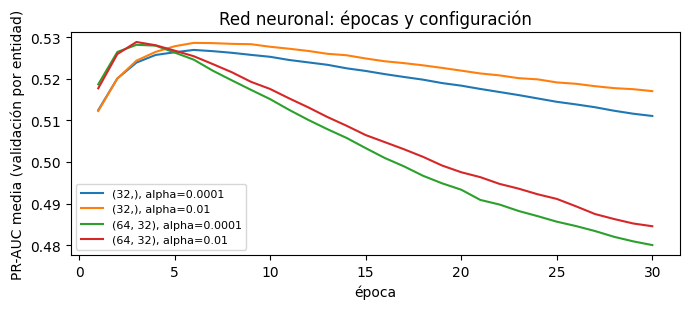

In [102]:
ARQUITECTURAS = [(32,), (64, 32)]
ALPHAS = [1e-4, 1e-2]
EPOCAS_MAX = 30
PLIEGUES_RED = PLIEGUES[:3]

def red_nueva(arq, alpha, semilla=SEMILLA):
    return MLPClassifier(hidden_layer_sizes=arq, alpha=alpha, learning_rate_init=1e-3,
                         batch_size=256, random_state=semilla)

def entrenar_por_epocas(red, Xa, ya, epocas, Xv=None, yv=None):
    aps = []
    for _ in range(epocas):
        red.partial_fit(Xa, ya, classes=np.array([0, 1]))
        if Xv is not None:
            aps.append(average_precision_score(yv, red.predict_proba(Xv)[:, 1]))
    return red, aps

def ajustar_red(Xa, ya):
    prep = clone(prep_lineal).fit(Xa)
    red, _ = entrenar_por_epocas(red_nueva(ARQ, ALPHA), prep.transform(Xa), ya, EPOCAS)
    return Pipeline([("prep", prep), ("clf", red)])

if ENTRENAR_MODELOS:
    t0 = time.time()
    datos_red = []
    for a, v in PLIEGUES_RED:                       # el preprocesamiento se ajusta dentro de cada pliegue
        prep = clone(prep_lineal).fit(X_tr.iloc[a])
        datos_red.append((prep.transform(X_tr.iloc[a]), y_tr[a], prep.transform(X_tr.iloc[v]), y_tr[v]))

    filas, CURVAS_RED = [], {}
    for arq in ARQUITECTURAS:
        for alpha in ALPHAS:
            c = np.array([entrenar_por_epocas(red_nueva(arq, alpha), Xa, ya, EPOCAS_MAX, Xv, yv)[1]
                          for Xa, ya, Xv, yv in datos_red])
            CURVAS_RED[f"{arq}, alpha={alpha:g}"] = c.mean(axis=0)
            media = c.mean(axis=0); i = int(np.argmax(media))
            filas.append({"arquitectura": str(arq), "alpha": alpha, "mejor época": i + 1, "PR-AUC media": media[i],
                          "error estándar": c[:, i].std(ddof=1) / np.sqrt(len(c)), "PR-AUC última época": media[-1],
                          "_clave": (arq, alpha)})
    tabla_red = pd.DataFrame(filas)
    RESULTADOS["red_busqueda"] = (tabla_red, CURVAS_RED)
    nota("red_tiempo", f"Búsqueda de la red: {time.time() - t0:.0f} s")
else:
    tabla_red, CURVAS_RED = RESULTADOS["red_busqueda"]
    nota("red_tiempo")
display(tabla_red.drop(columns="_clave").round(4))

fig, ax = plt.subplots(figsize=(7, 3.2))
for etiqueta, media in CURVAS_RED.items():
    ax.plot(np.arange(1, len(media) + 1), media, label=etiqueta)
ax.set(xlabel="época", ylabel="PR-AUC media (validación por entidad)", title="Red neuronal: épocas y configuración")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

In [103]:
fila = tabla_red.loc[tabla_red["PR-AUC media"].idxmax()]
(ARQ, ALPHA), EPOCAS = fila["_clave"], int(fila["mejor época"])
print(f"Red elegida: capas {ARQ}, alpha={ALPHA:g}, {EPOCAS} épocas")

if ENTRENAR_MODELOS:
    # predicciones fuera de pliegue (los 5 pliegues) para el umbral
    oof_red = np.full(len(y_tr), np.nan)
    for a, v in PLIEGUES:
        prep = clone(prep_lineal).fit(X_tr.iloc[a])
        red, _ = entrenar_por_epocas(red_nueva(ARQ, ALPHA), prep.transform(X_tr.iloc[a]), y_tr[a], EPOCAS)
        oof_red[v] = red.predict_proba(prep.transform(X_tr.iloc[v]))[:, 1]

    # modelo final con todo el entrenamiento y 3 semillas
    prep_red = clone(prep_lineal).fit(X_tr)
    Z_tr, Z_te = prep_red.transform(X_tr), prep_red.transform(X_te)
    redes = {s: entrenar_por_epocas(red_nueva(ARQ, ALPHA, s), Z_tr, y_tr, EPOCAS)[0] for s in [SEMILLA, SEMILLA + 1, SEMILLA + 2]}
    ap_semillas = {s: average_precision_score(y_te, r.predict_proba(Z_te)[:, 1]) for s, r in redes.items()}
    red_final = redes[SEMILLA]
    n_param = sum(w.size for w in red_final.coefs_) + sum(b.size for b in red_final.intercepts_)
    nota("red", f"Entradas tras one-hot: {Z_tr.shape[1]} · parámetros de la red: {n_param:,}\n"
                f"PR-AUC en prueba según la semilla: { {s: round(v, 4) for s, v in ap_semillas.items()} } "
                f"· desviación {np.std(list(ap_semillas.values()), ddof=1):.4f}")
    red_pipe = Pipeline([("prep", prep_red), ("clf", red_final)])   # pasos ya ajustados
    registrar("Red neuronal", oof_red, red_final.predict_proba(Z_te)[:, 1], red_pipe, X_te, ajustar=ajustar_red)
else:
    nota("red")
    registrar("Red neuronal")

Red elegida: capas (64, 32), alpha=0.01, 3 épocas
Entradas tras one-hot: 471 · parámetros de la red: 32,321
PR-AUC en prueba según la semilla: {42: 0.5332, 43: 0.5335, 44: 0.5357} · desviación 0.0014
Red neuronal: PR-AUC fuera de pliegue 0.5293 · umbral F1 = 0.234  (cargado)


## 10. Selección automática del campeón y comparación en prueba (contratos de 2024)

### 10.1 Regla de selección

La regla se fija antes de mirar la prueba y usa solo las predicciones **fuera de pliegue** del entrenamiento:

1. **Métrica principal:** PR-AUC media de la validación cruzada por entidad.
2. **Elegibles:** los modelos que quedan a menos de **un error estándar** del mejor. El error estándar se calcula sobre las diferencias pliegue a pliegue (comparación **pareada**: mismo pliegue, mismas entidades), que es más preciso que comparar las dos medias por separado. Además, cada elegible debe superar a la línea base por más de dos errores estándar.
3. **Entre los elegibles, el más interpretable:** nivel 1, regresión logística y árbol de decisión; nivel 2, bosque aleatorio y Gradient Boosting; nivel 3, red neuronal. Si el modelo más simple ordena igual de bien, se prefiere porque una contraloría puede explicar por qué marcó un contrato.
4. **Desempates dentro del mismo nivel:** menor puntaje de Brier fuera de pliegue (probabilidades más fieles a la frecuencia real) y, si persiste el empate, mayor precisión en el `CAPACIDAD` (10 %) de contratos con mayor puntaje, que es lo que vería un equipo con capacidad de revisión limitada.
5. **La prueba solo confirma.** Si la PR-AUC del campeón en 2024 cae más de max(0,03; 3 errores estándar) frente a la validación cruzada, se emite una advertencia. No se cambia de campeón con la prueba: si se eligiera con ella, dejaría de ser una prueba.

La estabilidad entre pliegues y el peor ROC-AUC por modalidad (fuera de pliegue) se muestran como información; no entran en la decisión.

In [104]:
NIVEL = {"Regresión logística": 1, "Árbol de decisión": 1, "Bosque aleatorio": 2, "Gradient Boosting": 2, "Red neuronal": 3}
PK = f"precisión@{CAPACIDAD:.0%}"
K = len(PLIEGUES)
ee = lambda d: d.std(ddof=1) / np.sqrt(len(d))   # error estándar de una media de pliegues

def ap_por_pliegue(p):
    return np.array([average_precision_score(y_tr[v], p[v]) for _, v in PLIEGUES])

def precision_en_k(yd, p, frac=CAPACIDAD):
    k = max(1, int(round(frac * len(yd))))
    return yd[np.argsort(-p, kind="stable")[:k]].mean()

mod_tr = df.modalidad_de_contratacion.values[tr]
def peor_auc_modalidad(p):
    v = [roc_auc_score(y_tr[s], p[s]) for s in (mod_tr == mod for mod in pd.unique(mod_tr))
         if s.sum() >= 200 and 0 < y_tr[s].mean() < 1]
    return min(v) if v else np.nan

AP = {n: ap_por_pliegue(m["p_oof"]) for n, m in MODELOS.items()}
candidatos = [n for n in MODELOS if n != "Línea base"]
MEJOR_CV = max(candidatos, key=lambda n: AP[n].mean())

filas = []
for n in candidatos:
    d_mejor = AP[MEJOR_CV] - AP[n]
    d_base = AP[n] - AP["Línea base"]
    cerca = (n == MEJOR_CV) or (d_mejor.mean() <= ee(d_mejor))
    sobre_base = d_base.mean() > 2 * ee(d_base)
    filas.append({"modelo": n, "PR-AUC CV": AP[n].mean(), "desv. entre pliegues": AP[n].std(ddof=1),
                  "Δ vs mejor": -d_mejor.mean(), "EE pareado": 0.0 if n == MEJOR_CV else ee(d_mejor),
                  "supera base": sobre_base, "elegible": cerca and sobre_base, "nivel": NIVEL.get(n, 3),
                  "Brier OOF": brier_score_loss(y_tr, MODELOS[n]["p_oof"]),
                  f"{PK} OOF": precision_en_k(y_tr, MODELOS[n]["p_oof"]),
                  "peor ROC-AUC por modalidad": peor_auc_modalidad(MODELOS[n]["p_oof"])})
seleccion = pd.DataFrame(filas).set_index("modelo")
elegibles = seleccion[seleccion.elegible]

if elegibles.empty:
    CAMPEON = MEJOR_CV
    print("ADVERTENCIA: ningún modelo supera a la línea base por más de dos errores estándar; "
          "se reporta el de mejor PR-AUC en validación, pero el modelo no aporta información útil.")
else:
    orden = elegibles.assign(_brier=elegibles["Brier OOF"], _pk=-elegibles[f"{PK} OOF"]).sort_values(["nivel", "_brier", "_pk"])
    CAMPEON = orden.index[0]
REFERENCIA = CAMPEON   # las secciones siguientes analizan al campeón

display(seleccion.sort_values("PR-AUC CV", ascending=False).round(4))
print(f"Mejor PR-AUC en validación cruzada: {MEJOR_CV} ({AP[MEJOR_CV].mean():.4f})")
print(f"Elegibles (a menos de 1 EE pareado del mejor y por encima de la base): {list(elegibles.index)}")
print(f"CAMPEÓN: {CAMPEON} (nivel de interpretabilidad {NIVEL.get(CAMPEON, 3)})")
if CAMPEON != MEJOR_CV:
    print(f"  Se prefiere a {MEJOR_CV} porque su PR-AUC no es distinguible dentro de un error estándar "
          f"(Δ {seleccion.loc[CAMPEON, 'Δ vs mejor']:+.4f}, EE {seleccion.loc[CAMPEON, 'EE pareado']:.4f}) y es más interpretable.")

,PR-AUC CV,desv. entre pliegues,Δ vs mejor,EE pareado,supera base,elegible,nivel,Brier OOF,precisión@10% OOF,peor ROC-AUC por modalidad
modelo,,,,,,,,,,
Gradient Boosting,0.5506,0.0328,-0.0000,0.0000,True,True,2,0.1537,0.6559,0.6615
Bosque aleatorio,0.5371,0.0391,-0.0135,0.0031,True,False,2,0.1564,0.6441,0.6443
Red neuronal,0.5361,0.0302,-0.0145,0.0020,True,False,3,0.1579,0.6318,0.6454
Regresión logística,0.5045,0.0340,-0.0461,0.0008,True,False,1,0.2015,0.6027,0.6449
Árbol de decisión,0.4752,0.0371,-0.0754,0.0044,True,False,1,0.1656,0.5824,0.5798


Mejor PR-AUC en validación cruzada: Gradient Boosting (0.5506)
Elegibles (a menos de 1 EE pareado del mejor y por encima de la base): ['Gradient Boosting']
CAMPEÓN: Gradient Boosting (nivel de interpretabilidad 2)


### 10.2 Comparación en prueba

Cada modelo usa el umbral elegido con sus predicciones fuera de pliegue. Las diferencias frente al campeón se miden con bootstrap **pareado por entidad**: en cada remuestreo se calculan las métricas de todos los modelos sobre las mismas entidades. La columna `precisión@10%` es la proporción de sobrecostos entre el 10 % de contratos con mayor puntaje.

In [105]:
filas = []
for nombre, m in MODELOS.items():
    p, u = m["p_te"], m["umbral"]
    pred = p >= u
    filas.append({"modelo": nombre, "PR-AUC CV": AP[nombre].mean(),
                  "ROC-AUC": roc_auc_score(y_te, p), "PR-AUC": average_precision_score(y_te, p),
                  PK: precision_en_k(y_te, p),
                  "umbral": u, "precisión": precision_score(y_te, pred, zero_division=0),
                  "exhaustividad": recall_score(y_te, pred), "F1": f1_score(y_te, pred),
                  "% marcados": pred.mean(), "Brier": brier_score_loss(y_te, p)})
tabla = pd.DataFrame(filas).set_index("modelo")
display(tabla.round(3))

# confirmación del campeón en la prueba (no cambia la elección)
tolerancia = max(0.03, 3 * ee(AP[CAMPEON]))
caida = AP[CAMPEON].mean() - tabla.loc[CAMPEON, "PR-AUC"]
if caida > tolerancia:
    print(f"ADVERTENCIA: la PR-AUC del campeón cae {caida:.3f} de validación a prueba (tolerancia {tolerancia:.3f}). "
          "Puede haber un cambio entre años; revisar la sección 12.2 antes de usar el modelo.")
else:
    print(f"Confirmación: la PR-AUC del campeón en prueba ({tabla.loc[CAMPEON, 'PR-AUC']:.3f}) está dentro de la "
          f"tolerancia frente a la validación cruzada ({AP[CAMPEON].mean():.3f}; tolerancia {tolerancia:.3f}).")

# bootstrap pareado por entidad
rng = np.random.default_rng(SEMILLA)
pos_por_entidad = pd.Series(np.arange(len(y_te))).groupby(g_te).indices
entidades = np.array(list(pos_por_entidad))
boot = {n: {"ap": [], "auc": []} for n in MODELOS}
for _ in range(N_BOOT):
    ii = np.concatenate([pos_por_entidad[e] for e in rng.choice(entidades, len(entidades), replace=True)])
    if y_te[ii].min() == y_te[ii].max():
        continue
    for n, m in MODELOS.items():
        boot[n]["ap"].append(average_precision_score(y_te[ii], m["p_te"][ii]))
        boot[n]["auc"].append(roc_auc_score(y_te[ii], m["p_te"][ii]))
boot = {n: {k: np.array(v) for k, v in d.items()} for n, d in boot.items()}

ic = pd.DataFrame({n: {"PR-AUC": f"{np.median(d['ap']):.3f} [{np.percentile(d['ap'], 2.5):.3f}, {np.percentile(d['ap'], 97.5):.3f}]",
                       "ROC-AUC": f"{np.median(d['auc']):.3f} [{np.percentile(d['auc'], 2.5):.3f}, {np.percentile(d['auc'], 97.5):.3f}]",
                       f"Δ PR-AUC vs {CAMPEON}": "—" if n == CAMPEON else
                           f"{np.median(d['ap'] - boot[CAMPEON]['ap']):+.3f} "
                           f"[{np.percentile(d['ap'] - boot[CAMPEON]['ap'], 2.5):+.3f}, "
                           f"{np.percentile(d['ap'] - boot[CAMPEON]['ap'], 97.5):+.3f}]"}
                   for n, d in boot.items()}).T
print(f"\nIntervalos de 95 % (bootstrap por entidad, {len(boot[CAMPEON]['ap'])} remuestreos):")
display(ic)
print("Una diferencia cuyo intervalo no contiene 0 es distinguible del azar de qué entidades tocan en la prueba.")

print("\nPrueba según si la entidad ya contrataba en el período de entrenamiento:")
print(f"  tasa de sobrecosto: entidades conocidas {y_te[~ENTIDAD_NUEVA].mean():.3f} ({(~ENTIDAD_NUEVA).sum():,} contratos) · "
      f"nuevas {y_te[ENTIDAD_NUEVA].mean():.3f} ({ENTIDAD_NUEVA.sum():,} contratos)")
filas = {}
for n, m in MODELOS.items():
    fila = {}
    for etiqueta, s in [("conocidas", ~ENTIDAD_NUEVA), ("nuevas", ENTIDAD_NUEVA)]:
        ok = 0 < y_te[s].mean() < 1
        fila[f"PR-AUC {etiqueta}"] = average_precision_score(y_te[s], m["p_te"][s]) if ok else np.nan
        fila[f"PR-AUC / tasa {etiqueta}"] = fila[f"PR-AUC {etiqueta}"] / y_te[s].mean() if ok else np.nan
        fila[f"ROC-AUC {etiqueta}"] = roc_auc_score(y_te[s], m["p_te"][s]) if ok else np.nan
    filas[n] = fila
display(pd.DataFrame(filas).T.round(3))
print("La PR-AUC depende de la tasa de positivos de cada grupo; para comparar grupos, mirar PR-AUC / tasa (cuántas veces "
      "supera al azar) o el ROC-AUC, que no depende de la tasa.")

,PR-AUC CV,ROC-AUC,PR-AUC,precisión@10%,umbral,precisión,exhaustividad,F1,% marcados,Brier
modelo,,,,,,,,,,
Línea base,0.255,0.500,0.255,0.261,1.000,0.000,0.000,0.000,0.000,0.190
Regresión logística,0.504,0.745,0.490,0.586,0.477,0.407,0.718,0.519,0.450,0.206
Árbol de decisión,0.475,0.726,0.469,0.571,0.261,0.424,0.617,0.502,0.371,0.166
Bosque aleatorio,0.537,0.779,0.548,0.656,0.273,0.459,0.691,0.551,0.383,0.153
Gradient Boosting,0.551,0.783,0.551,0.648,0.263,0.461,0.699,0.555,0.386,0.152
Red neuronal,0.536,0.769,0.533,0.641,0.234,0.406,0.787,0.536,0.493,0.157


Confirmación: la PR-AUC del campeón en prueba (0.551) está dentro de la tolerancia frente a la validación cruzada (0.551; tolerancia 0.044).

Intervalos de 95 % (bootstrap por entidad, 500 remuestreos):


,PR-AUC,ROC-AUC,Δ PR-AUC vs Gradient Boosting
Línea base,"0.255 [0.244, 0.266]","0.500 [0.500, 0.500]","-0.296 [-0.314, -0.279]"
Regresión logística,"0.490 [0.468, 0.516]","0.744 [0.732, 0.757]","-0.061 [-0.070, -0.050]"
Árbol de decisión,"0.469 [0.449, 0.489]","0.727 [0.716, 0.738]","-0.083 [-0.096, -0.065]"
Bosque aleatorio,"0.548 [0.529, 0.570]","0.779 [0.771, 0.788]","-0.003 [-0.013, +0.012]"
Gradient Boosting,"0.551 [0.529, 0.575]","0.783 [0.772, 0.793]",—
Red neuronal,"0.533 [0.507, 0.560]","0.769 [0.756, 0.780]","-0.018 [-0.025, -0.011]"


Una diferencia cuyo intervalo no contiene 0 es distinguible del azar de qué entidades tocan en la prueba.

Prueba según si la entidad ya contrataba en el período de entrenamiento:
  tasa de sobrecosto: entidades conocidas 0.257 (66,127 contratos) · nuevas 0.176 (1,896 contratos)


,PR-AUC conocidas,PR-AUC / tasa conocidas,ROC-AUC conocidas,PR-AUC nuevas,PR-AUC / tasa nuevas,ROC-AUC nuevas
Línea base,0.257,1.000,0.500,0.176,1.000,0.500
Regresión logística,0.494,1.923,0.745,0.306,1.741,0.695
Árbol de decisión,0.472,1.839,0.726,0.296,1.685,0.696
Bosque aleatorio,0.552,2.149,0.780,0.340,1.935,0.733
Gradient Boosting,0.554,2.159,0.783,0.359,2.043,0.746
Red neuronal,0.537,2.090,0.770,0.330,1.876,0.720


La PR-AUC depende de la tasa de positivos de cada grupo; para comparar grupos, mirar PR-AUC / tasa (cuántas veces supera al azar) o el ROC-AUC, que no depende de la tasa.


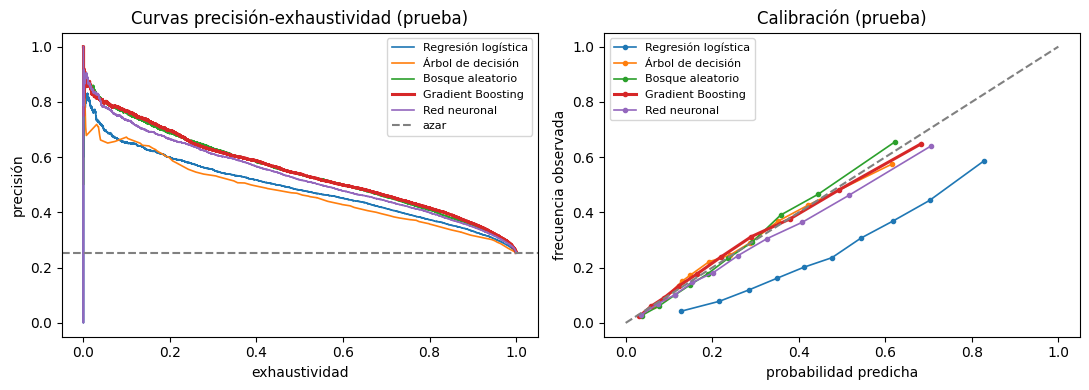

Matriz de confusión del campeón (Gradient Boosting) con umbral 0.263 [filas = real, columnas = predicho]:
[[36561 14150]
 [ 5215 12097]]


In [106]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for nombre, m in MODELOS.items():
    if nombre == "Línea base":
        continue
    prec, rec, _ = precision_recall_curve(y_te, m["p_te"])
    axes[0].plot(rec, prec, label=nombre, lw=2.2 if nombre == CAMPEON else 1.2)
    frac, media = calibration_curve(y_te, m["p_te"], n_bins=10, strategy="quantile")
    axes[1].plot(media, frac, marker="o", ms=3, label=nombre, lw=2.2 if nombre == CAMPEON else 1.2)
axes[0].axhline(y_te.mean(), color="gray", ls="--", label="azar")
axes[0].set(xlabel="exhaustividad", ylabel="precisión", title="Curvas precisión-exhaustividad (prueba)")
axes[1].plot([0, 1], [0, 1], color="gray", ls="--")
axes[1].set(xlabel="probabilidad predicha", ylabel="frecuencia observada", title="Calibración (prueba)")
axes[0].legend(fontsize=8); axes[1].legend(fontsize=8); plt.tight_layout(); plt.show()

m = MODELOS[CAMPEON]
print(f"Matriz de confusión del campeón ({CAMPEON}) con umbral {m['umbral']:.3f} [filas = real, columnas = predicho]:")
print(confusion_matrix(y_te, m["p_te"] >= m["umbral"]))

In [107]:
print(f"Desempeño del campeón ({CAMPEON}) por modalidad (prueba, modalidades con al menos 200 contratos):")
mod_te = df.modalidad_de_contratacion.values[te]
filas = []
for mod in pd.unique(mod_te):
    s = mod_te == mod
    if s.sum() >= 200 and 0 < y_te[s].mean() < 1:
        filas.append({"modalidad": mod, "contratos": int(s.sum()), "tasa": y_te[s].mean(),
                      "PR-AUC": average_precision_score(y_te[s], m["p_te"][s]),
                      "ROC-AUC": roc_auc_score(y_te[s], m["p_te"][s])})
por_modalidad = pd.DataFrame(filas).sort_values("contratos", ascending=False).set_index("modalidad")
display(por_modalidad.round(3))
print("Si el ROC-AUC dentro de cada modalidad es mucho menor que el global, parte del desempeño viene de "
      "distinguir modalidades con tasas distintas, no de ordenar contratos dentro de cada una.")

Desempeño del campeón (Gradient Boosting) por modalidad (prueba, modalidades con al menos 200 contratos):


,contratos,tasa,PR-AUC,ROC-AUC
modalidad,,,,
Mínima cuantía,40126,0.208,0.473,0.775
Contratación Directa (con ofertas),8260,0.228,0.503,0.770
Selección Abreviada de Menor Cuantía,6696,0.411,0.654,0.735
Contratación régimen especial (con ofertas),4961,0.269,0.504,0.756
Selección abreviada subasta inversa,4938,0.325,0.631,0.795
Licitación pública,1185,0.603,0.823,0.783
Concurso de méritos abierto,1165,0.271,0.501,0.731
Licitación pública Obra Publica,573,0.532,0.641,0.643


Si el ROC-AUC dentro de cada modalidad es mucho menor que el global, parte del desempeño viene de distinguir modalidades con tasas distintas, no de ordenar contratos dentro de cada una.


### 10.3 Curva de aprendizaje: ¿más datos de entrenamiento cambiarían el resultado?

El entrenamiento usa tres años completos y la prueba el cuarto, así que la proporción entrenamiento/prueba la fija el calendario y no un 80/20 elegido a mano. Para verificar que la cantidad de datos no limita al campeón, se reentrena (con los hiperparámetros ya elegidos) con el 25 %, 50 % y 75 % de las **entidades** de entrenamiento, dos veces cada fracción, y se mide la PR-AUC en 2024; el punto del 100 % es el modelo final. Si la curva ya está plana entre el 75 % y el 100 %, agregar más datos no la movería de forma apreciable. Es un diagnóstico: no cambia ninguna decisión.

Curva de aprendizaje: 68 s


,contratos,media,desviacion
fracción,,,
0.25,46024.5,0.5158,0.0037
0.50,81601.0,0.5319,0.0042
0.75,124175.0,0.5411,0.0027
1.00,176495.0,0.5511,NaN


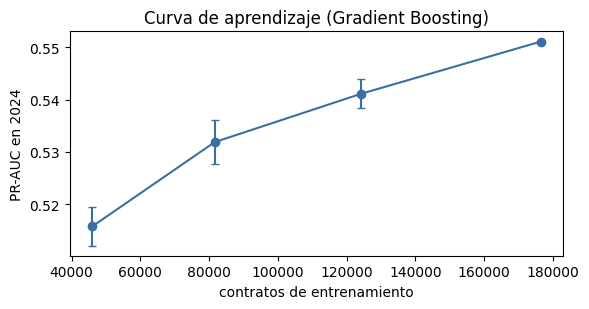

Pasar del 75 % al 100 % del entrenamiento cambia la PR-AUC en +0.0100.
Si esa ganancia es pequeña frente al ancho del intervalo de confianza de la sección 10.2, entrenar con más datos no cambiaría el resultado de forma apreciable.


In [108]:
FRACCIONES, REPETICIONES = [0.25, 0.5, 0.75], 2
if ENTRENAR_MODELOS:
    rng_curva = np.random.default_rng(SEMILLA)
    ent_tr = np.unique(g_tr)
    ajustar_campeon = MODELOS[CAMPEON]["ajustar"]
    t0 = time.time()
    filas = []
    for f in FRACCIONES:
        for _ in range(REPETICIONES):
            elegidas = rng_curva.choice(ent_tr, int(round(f * len(ent_tr))), replace=False)
            s = np.where(np.isin(g_tr, elegidas))[0]
            mod = ajustar_campeon(X_tr.iloc[s], y_tr[s])
            filas.append({"fracción": f, "contratos": len(s),
                          "PR-AUC prueba": average_precision_score(y_te, mod.predict_proba(X_te)[:, 1])})
    filas.append({"fracción": 1.0, "contratos": len(y_tr), "PR-AUC prueba": average_precision_score(y_te, MODELOS[CAMPEON]["p_te"])})
    curva = (pd.DataFrame(filas).groupby("fracción")
             .agg(contratos=("contratos", "mean"), media=("PR-AUC prueba", "mean"), desviacion=("PR-AUC prueba", "std")))
    RESULTADOS["curva_aprendizaje"] = curva
    nota("curva_tiempo", f"Curva de aprendizaje: {time.time() - t0:.0f} s")
    guardar_resultados()
else:
    curva = RESULTADOS["curva_aprendizaje"]
    nota("curva_tiempo")
display(curva.round(4))

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.errorbar(curva.contratos, curva.media, yerr=curva.desviacion.fillna(0), marker="o", capsize=3, color="#3b6ea5")
ax.set(xlabel="contratos de entrenamiento", ylabel=f"PR-AUC en {ANIO_PRUEBA}", title=f"Curva de aprendizaje ({CAMPEON})")
plt.tight_layout(); plt.show()

ganancia = curva.loc[1.0, "media"] - curva.loc[0.75, "media"]
print(f"Pasar del 75 % al 100 % del entrenamiento cambia la PR-AUC en {ganancia:+.4f}.")
print("Si esa ganancia es pequeña frente al ancho del intervalo de confianza de la sección 10.2, "
      "entrenar con más datos no cambiaría el resultado de forma apreciable.")

## 11. Qué impulsa el riesgo

### 11.1 Importancia de variables del campeón (permutación sobre el conjunto de prueba)

Se permuta cada variable y se mide cuánto cae la PR-AUC del campeón. Mide cuánto **depende este modelo** de cada variable, no si la variable causa el sobrecosto; con variables correlacionadas (precio base y valor adjudicado), la importancia se reparte entre ellas.

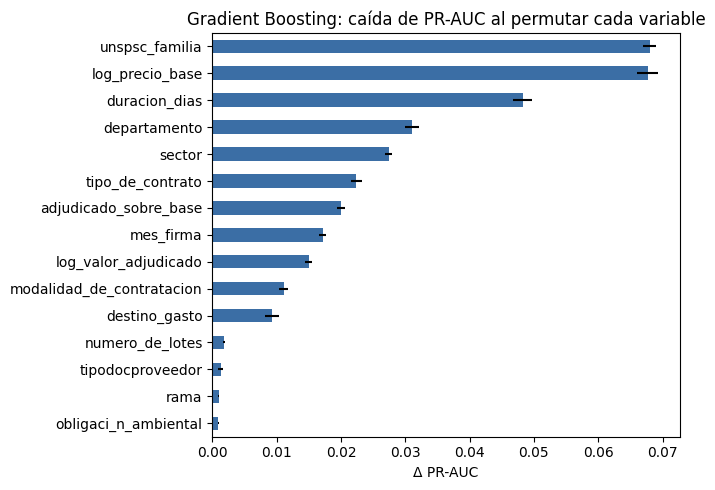

Cinco variables más importantes: ['unspsc_familia', 'log_precio_base', 'duracion_dias', 'departamento', 'sector']


In [109]:
m = MODELOS[CAMPEON]
if ENTRENAR_MODELOS:
    imp = permutation_importance(m["predictor"], m["X_prueba"], y_te, scoring="average_precision",
                                 n_repeats=5, random_state=SEMILLA, n_jobs=-1)
    IMPORTANCIA = pd.DataFrame({"media": imp.importances_mean, "desviacion": imp.importances_std},
                               index=m["X_prueba"].columns)
    RESULTADOS["importancia"] = IMPORTANCIA
    guardar_resultados()
else:
    IMPORTANCIA = RESULTADOS["importancia"]
importancia = IMPORTANCIA["media"].sort_values()
ax = importancia.tail(15).plot.barh(figsize=(7, 5), color="#3b6ea5",
                                    xerr=IMPORTANCIA["desviacion"][importancia.tail(15).index])
ax.set(title=f"{CAMPEON}: caída de PR-AUC al permutar cada variable", xlabel="Δ PR-AUC")
plt.tight_layout(); plt.show()
TOP_PRINCIPAL = importancia.sort_values(ascending=False).head(5).index.tolist()
print("Cinco variables más importantes:", TOP_PRINCIPAL)

### 11.2 Cómo cambia el riesgo con cada variable (dependencia parcial)

La importancia dice **cuánto** depende el modelo de una variable, pero no **en qué dirección**. La dependencia parcial lo muestra: se toma una muestra de contratos de prueba, se fija la variable en un valor para todos ellos (dejando lo demás como está) y se promedia la probabilidad predicha; se repite para varios valores. En las numéricas se usan valores entre los percentiles 5 y 95; en las categóricas, las 12 categorías más frecuentes. Como la importancia, describe al **modelo**, no una relación causal.

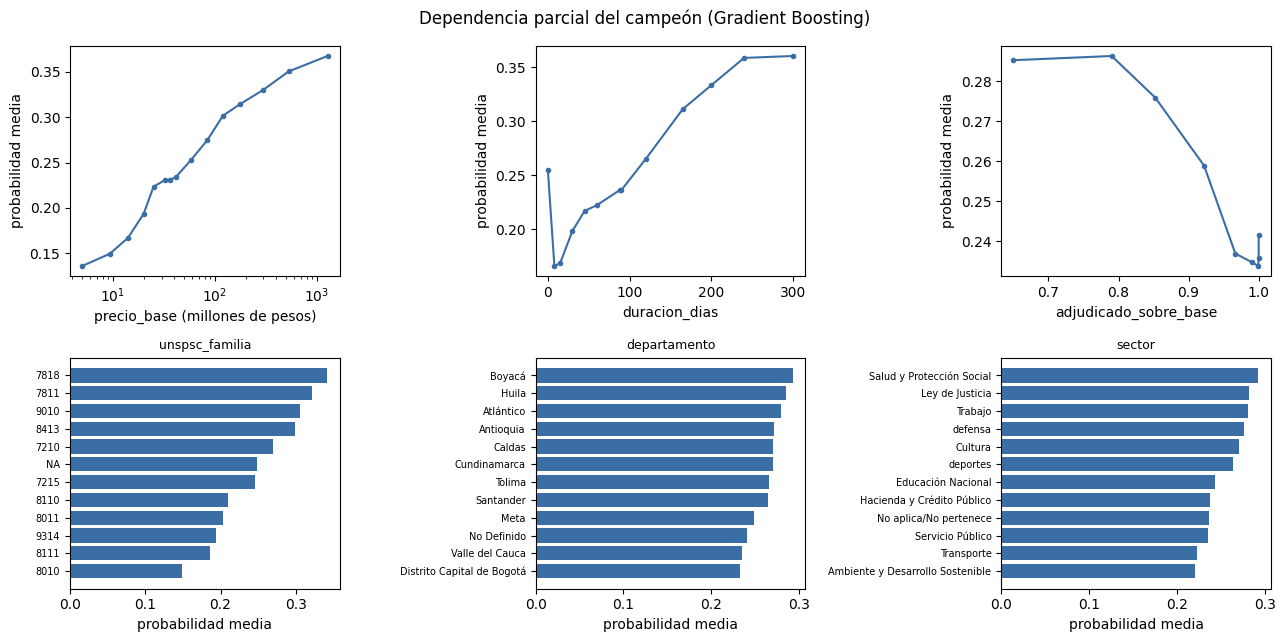

In [110]:
def dependencia_parcial(modelo, Xm, var, valores):
    salida = []
    for valor in valores:
        Z = Xm.copy()
        if isinstance(Z[var].dtype, pd.CategoricalDtype):
            Z[var] = pd.Categorical([valor] * len(Z), categories=Z[var].cat.categories)
        else:
            Z[var] = valor
        salida.append(modelo.predict_proba(Z)[:, 1].mean())
    return np.array(salida)

VARS_DEPENDENCIA = ([v for v in importancia.sort_values(ascending=False).index if v in NUMERICAS][:3]
                    + [v for v in importancia.sort_values(ascending=False).index if v in CATEGORICAS][:3])
if ENTRENAR_MODELOS:
    muestra_pd = m["X_prueba"].sample(min(3000, len(m["X_prueba"])), random_state=SEMILLA)
    DEPENDENCIA = {}
    for var in VARS_DEPENDENCIA:
        if var in NUMERICAS:
            valores = np.unique(np.nanquantile(muestra_pd[var].astype(float), np.linspace(0.05, 0.95, 15)))
        else:
            valores = muestra_pd[var].astype(str).value_counts().index[:12].tolist()
        DEPENDENCIA[var] = pd.DataFrame({"valor": valores,
                                         "probabilidad media": dependencia_parcial(m["predictor"], muestra_pd, var, valores)})
    RESULTADOS["dependencia"] = DEPENDENCIA
    guardar_resultados()
else:
    DEPENDENCIA = RESULTADOS["dependencia"]

fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, (var, t) in zip(axes.ravel(), DEPENDENCIA.items()):
    if var in NUMERICAS:
        x = np.expm1(t["valor"]) / 1e6 if var.startswith("log_") else t["valor"]
        ax.plot(x, t["probabilidad media"], marker="o", ms=3, color="#3b6ea5")
        ax.set_xlabel(var.replace("log_", "") + (" (millones de pesos)" if var.startswith("log_") else ""))
        if var.startswith("log_"):
            ax.set_xscale("log")
    else:
        tt = t.sort_values("probabilidad media")
        ax.barh(tt["valor"].astype(str), tt["probabilidad media"], color="#3b6ea5")
        ax.set_xlabel("probabilidad media"); ax.set_title(var, fontsize=9)
        ax.tick_params(axis="y", labelsize=7)
        continue
    ax.set_ylabel("probabilidad media")
for ax in axes.ravel()[len(DEPENDENCIA):]:
    ax.axis("off")
plt.suptitle(f"Dependencia parcial del campeón ({CAMPEON})"); plt.tight_layout(); plt.show()

## 12. Robustez

Se reentrenan el campeón y la regresión logística (como referencia simple) con los hiperparámetros ya elegidos, cambiando una cosa a la vez:

* **12.1 Corte del objetivo:** los dos escenarios de la sección 4.2 (nominal y legal), con la misma partición 2021-2023 contra 2024. Si el desempeño y las cinco variables principales del campeón coinciden, la conclusión no depende de cómo se limpió el objetivo.
* **12.2 Año de prueba:** segunda ventana temporal (`VENTANA_2`: entrenar 2021-2022 y evaluar 2023) con el objetivo principal. Si el nivel de desempeño y la diferencia entre el campeón y la logística se mantienen, el resultado no depende de un solo año. Aviso: los hiperparámetros se eligieron con validación cruzada que incluía 2023, así que esta ventana no es una prueba totalmente independiente; sirve para ver la estabilidad entre años, no para reportar un desempeño.

In [111]:
MODELOS_ROBUSTEZ = list(dict.fromkeys([CAMPEON, "Regresión logística"]))

def ajuste_rapido(d, anios_a, anio_b):
    Xa, ya = construir_X(d), d.sobrecosto.values
    a = np.where(np.isin(d.anio_firma.values, anios_a))[0]
    b = np.where(d.anio_firma.values == anio_b)[0]
    fila = {"contratos entren.": len(a), "contratos prueba": len(b), "tasa prueba": round(ya[b].mean(), 3)}
    for n in MODELOS_ROBUSTEZ:
        mod = MODELOS[n]["ajustar"](Xa.iloc[a], ya[a])
        p = mod.predict_proba(Xa.iloc[b])[:, 1]
        fila[f"PR-AUC {n}"] = round(average_precision_score(ya[b], p), 3)
        fila[f"ROC-AUC {n}"] = round(roc_auc_score(ya[b], p), 3)
        if n == CAMPEON:
            im = permutation_importance(mod, Xa.iloc[b], ya[b], scoring="average_precision",
                                        n_repeats=3, random_state=SEMILLA, n_jobs=-1)
            fila["top 5 (campeón)"] = pd.Series(im.importances_mean, index=Xa.columns).sort_values(ascending=False).head(5).index.tolist()
    return fila

ventana_1 = f"{ANIOS_ENTRENAMIENTO[0]}-{ANIOS_ENTRENAMIENTO[-1]} → {ANIO_PRUEBA}"
ventana_2 = f"{VENTANA_2[0][0]}-{VENTANA_2[0][-1]} → {VENTANA_2[1]}"
if ENTRENAR_MODELOS:
    t0 = time.time()
    robustez = pd.DataFrame({
        f"12.1 objetivo nominal · {ventana_1}": ajuste_rapido(ESCENARIOS["nominal"], ANIOS_ENTRENAMIENTO, ANIO_PRUEBA),
        f"12.1 objetivo legal · {ventana_1}": ajuste_rapido(ESCENARIOS["legal"], ANIOS_ENTRENAMIENTO, ANIO_PRUEBA),
        f"12.2 objetivo {CORTE_PRINCIPAL} · {ventana_2}": ajuste_rapido(ESCENARIOS[CORTE_PRINCIPAL], *VENTANA_2),
    }).T
    RESULTADOS["robustez"] = robustez
    nota("robustez_tiempo", f"Robustez: {time.time() - t0:.0f} s")
    guardar_resultados()
else:
    robustez = RESULTADOS["robustez"]
    nota("robustez_tiempo")
display(robustez)

f_nom, f_leg, f_v2 = robustez.index
comunes = set(robustez.loc[f_nom, "top 5 (campeón)"]) & set(robustez.loc[f_leg, "top 5 (campeón)"])
comunes_v2 = set(robustez.loc[f_v2, "top 5 (campeón)"]) & set(robustez.loc[f"12.1 objetivo {CORTE_PRINCIPAL} · {ventana_1}", "top 5 (campeón)"])
print(f"12.1 · variables en el top 5 de ambos escenarios del objetivo: {len(comunes)} de 5 -> {sorted(comunes)}")
print(f"12.2 · variables en el top 5 de ambas ventanas temporales: {len(comunes_v2)} de 5 -> {sorted(comunes_v2)}")
pr_v1 = robustez.loc[f"12.1 objetivo {CORTE_PRINCIPAL} · {ventana_1}", f"PR-AUC {CAMPEON}"]
pr_v2 = robustez.loc[f_v2, f"PR-AUC {CAMPEON}"]
print(f"12.2 · PR-AUC del campeón: {pr_v1:.3f} ({ventana_1}) frente a {pr_v2:.3f} ({ventana_2})")
if CAMPEON != "Regresión logística":
    for f in (f"12.1 objetivo {CORTE_PRINCIPAL} · {ventana_1}", f_v2):
        print(f"       ventaja del campeón sobre la logística en {f.split('· ')[-1]}: "
              f"{robustez.loc[f, f'PR-AUC {CAMPEON}'] - robustez.loc[f, 'PR-AUC Regresión logística']:+.3f}")

Robustez: 371 s


,contratos entren.,contratos prueba,tasa prueba,PR-AUC Gradient Boosting,ROC-AUC Gradient Boosting,top 5 (campeón),PR-AUC Regresión logística,ROC-AUC Regresión logística
12.1 objetivo nominal · 2021-2023 → 2024,174956,67617,0.25,0.544,0.782,"[unspsc_familia, log_precio_base, duracion_dia...",0.48,0.742
12.1 objetivo legal · 2021-2023 → 2024,176495,68023,0.255,0.551,0.783,"[log_precio_base, unspsc_familia, duracion_dia...",0.49,0.745
12.2 objetivo legal · 2021-2022 → 2023,111506,64989,0.264,0.568,0.785,"[unspsc_familia, log_precio_base, duracion_dia...",0.518,0.753


12.1 · variables en el top 5 de ambos escenarios del objetivo: 5 de 5 -> ['departamento', 'duracion_dias', 'log_precio_base', 'sector', 'unspsc_familia']
12.2 · variables en el top 5 de ambas ventanas temporales: 5 de 5 -> ['departamento', 'duracion_dias', 'log_precio_base', 'sector', 'unspsc_familia']
12.2 · PR-AUC del campeón: 0.551 (2021-2023 → 2024) frente a 0.568 (2021-2022 → 2023)
       ventaja del campeón sobre la logística en 2021-2023 → 2024: +0.061
       ventaja del campeón sobre la logística en 2021-2022 → 2023: +0.050


## 13. Magnitud del problema y valor de priorizar

### 13.1 ¿Cuánto suman los sobrecostos?

El monto de la adición es `valor final − valor adjudicado` en los contratos con sobrecosto del escenario principal (ya sin los errores de registro de la sección 4.2), en pesos corrientes de cada año. **El modelo no predice este monto: solo si el sobrecosto ocurre.** El monto sirve para dimensionar el problema y para medir, en la sección 13.2, qué parte de los pesos de sobrecosto quedaría cubierta al revisar primero los contratos que el modelo señala.

,contratos,con_sobrecosto,valor adjudicado (miles de millones),adiciones (miles de millones),tasa,adiciones / valor adjudicado
anio_firma,,,,,,
2021,50742,12116,25425.987,5170.032,0.239,0.203
2022,60764,15813,28001.123,4840.839,0.260,0.173
2023,64989,17152,30866.265,5105.534,0.264,0.165
2024,68023,17312,28180.989,4602.905,0.255,0.163


Adiciones 2021-2024: 19.72 billones de pesos en 62,393 contratos (17.5% del valor adjudicado de todos los contratos)
Crecimiento mediano de un contrato con sobrecosto: 39.5% sobre lo adjudicado
Concentración: el 1% de los contratos con sobrecosto de mayor monto suma el 43% de las adiciones · el 10% de los contratos con sobrecosto de mayor monto suma el 82% de las adiciones · el 50% de los contratos con sobrecosto de mayor monto suma el 98% de las adiciones


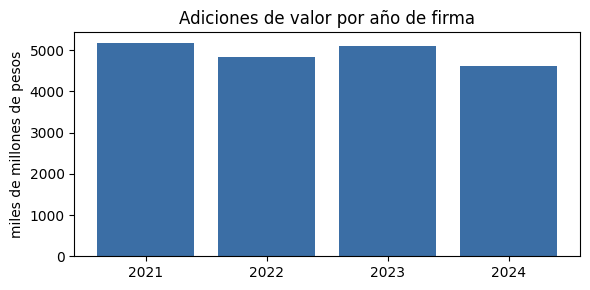

In [112]:
ADICION = np.where(df.sobrecosto == 1, df.valor_final - df.valor_adjudicado, 0.0)
mag = (df.assign(adicion=ADICION).groupby("anio_firma")
         .agg(contratos=("sobrecosto", "size"), con_sobrecosto=("sobrecosto", "sum"),
              valor_adjudicado=("valor_adjudicado", "sum"), adiciones=("adicion", "sum")))
mag["tasa"] = mag.con_sobrecosto / mag.contratos
mag["adiciones / valor adjudicado"] = mag.adiciones / mag.valor_adjudicado
mag[["valor_adjudicado", "adiciones"]] /= 1e9
MAGNITUD = mag.rename(columns={"valor_adjudicado": "valor adjudicado (miles de millones)",
                               "adiciones": "adiciones (miles de millones)"})
display(MAGNITUD.round(3))

positivos = np.sort(ADICION[ADICION > 0])[::-1]
CONCENTRACION = {f"{q:.0%}": positivos[:max(1, int(len(positivos) * q))].sum() / positivos.sum() for q in (0.01, 0.10, 0.50)}
crec_pos = (df.valor_final / df.valor_adjudicado)[df.sobrecosto == 1]
print(f"Adiciones {min(ANIOS)}-{max(ANIOS)}: {ADICION.sum() / 1e12:,.2f} billones de pesos en {int(df.sobrecosto.sum()):,} contratos "
      f"({ADICION.sum() / df.valor_adjudicado.sum():.1%} del valor adjudicado de todos los contratos)")
print(f"Crecimiento mediano de un contrato con sobrecosto: {crec_pos.median() - 1:.1%} sobre lo adjudicado")
print("Concentración: " + " · ".join(f"el {q} de los contratos con sobrecosto de mayor monto suma el {v:.0%} de las adiciones"
                                      for q, v in CONCENTRACION.items()))

fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(MAGNITUD.index.astype(str), MAGNITUD["adiciones (miles de millones)"], color="#3b6ea5")
ax.set(ylabel="miles de millones de pesos", title="Adiciones de valor por año de firma")
plt.tight_layout(); plt.show()

### 13.2 Curva de ganancia: ¿cuánto se encuentra revisando primero lo que señala el modelo? (prueba 2024)

Se ordenan los contratos de 2024 por la probabilidad del campeón y se mide qué parte de los sobrecostos, y de los pesos de sobrecosto, se encuentra al revisar el primer 1 %, 5 %, 10 %, 20 % o 30 %. Se compara con dos criterios sin modelo: **al azar** (la diagonal) y **revisar primero los contratos de mayor valor adjudicado**, que es lo que haría un equipo sin herramienta. La logística aparece como referencia de un modelo simple. Es una evaluación retrospectiva: simula haber usado el modelo durante 2024.

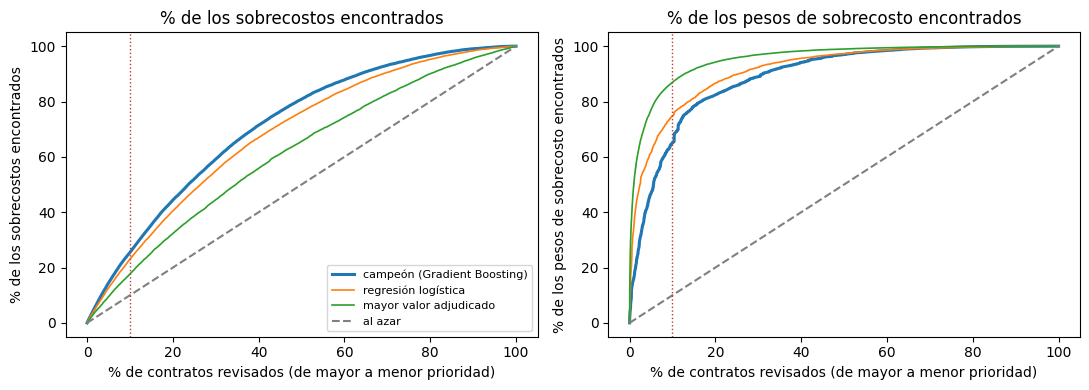

contratos revisados  \
revisar criterio                                           
1%      campeón (Gradient Boosting)                  680   
        regresión logística                          680   
        mayor valor adjudicado                       680   
5%      campeón (Gradient Boosting)                 3401   
        regresión logística                         3401   
        mayor valor adjudicado                      3401   
10%     campeón (Gradient Boosting)                 6802   
        regresión logística                         6802   
        mayor valor adjudicado                      6802   
20%     campeón (Gradient Boosting)                13605   
        regresión logística                        13605   
        mayor valor adjudicado                     13605   
30%     campeón (Gradient Boosting)                20407   
        regresión logística                        20407   
        mayor valor adjudicado                     20407   

                                     sobrecostos encontrados  precisión  \
revisar criterio                                                          
1%      campeón (Gradient Boosting)                      553      0.813   
        regresión logística                              507      0.746   
        mayor valor adjudicado                           372      0.547   
5%      campeón (Gradient Boosting)                     2505      0.737   
        regresión logística                             2182      0.642   
        mayor valor adjudicado                          1640      0.482   
10%     campeón (Gradient Boosting)                     4411      0.648   
        regresión logística                             3989      0.586   
        mayor valor adjudicado                          3060      0.450   
20%     campeón (Gradient Boosting)                     7690      0.565   
        regresión logística                             7006      0.515   
        mayor valor adjudicado                          5592      0.411   
30%     campeón (Gradient Boosting)                    10248      0.502   
        regresión logística                             9510      0.466   
        mayor valor adjudicado                          7708      0.378   

                                     % de los sobrecostos  \
revisar criterio                                            
1%      campeón (Gradient Boosting)                 0.032   
        regresión logística                         0.029   
        mayor valor adjudicado                      0.021   
5%      campeón (Gradient Boosting)                 0.145   
        regresión logística                         0.126   
        mayor valor adjudicado                      0.095   
10%     campeón (Gradient Boosting)                 0.255   
        regresión logística                         0.230   
        mayor valor adjudicado                      0.177   
20%     campeón (Gradient Boosting)                 0.444   
        regresión logística                         0.405   
        mayor valor adjudicado                      0.323   
30%     campeón (Gradient Boosting)                 0.592   
        regresión logística                         0.549   
        mayor valor adjudicado                      0.445   

                                     % de los pesos de sobrecosto  \
revisar criterio                                                    
1%      campeón (Gradient Boosting)                         0.162   
        regresión logística                                 0.349   
        mayor valor adjudicado                              0.502   
5%      campeón (Gradient Boosting)                         0.468   
        regresión logística                                 0.616   
        mayor valor adjudicado                              0.770   
10%     campeón (Gradient Boosting)                         0.651   
        regresión logística                                 0.748   
        mayo

Al azar, la precisión es la tasa de 2024 (25.5%) y se encuentra el mismo % de sobrecostos que de contratos revisados.


In [113]:
ad_te = ADICION[te]
def capturado(orden, w):
    return np.concatenate([[0.0], np.cumsum(w[orden])]) / w.sum()

ORDENES = {f"campeón ({CAMPEON})": np.argsort(-MODELOS[CAMPEON]["p_te"], kind="stable")}
if CAMPEON != "Regresión logística":
    ORDENES["regresión logística"] = np.argsort(-MODELOS["Regresión logística"]["p_te"], kind="stable")
ORDENES["mayor valor adjudicado"] = np.argsort(-df.valor_adjudicado.values[te], kind="stable")
FRAC = np.arange(len(y_te) + 1) / len(y_te)
GANANCIA = {n: {"conteo": capturado(o, y_te.astype(float)), "pesos": capturado(o, ad_te)} for n, o in ORDENES.items()}

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, clave, titulo in [(axes[0], "conteo", "% de los sobrecostos encontrados"),
                          (axes[1], "pesos", "% de los pesos de sobrecosto encontrados")]:
    for n, g in GANANCIA.items():
        ax.plot(100 * FRAC, 100 * g[clave], label=n, lw=2.2 if n.startswith("campeón") else 1.2)
    ax.plot([0, 100], [0, 100], color="gray", ls="--", label="al azar")
    ax.axvline(100 * CAPACIDAD, color="#c0392b", ls=":", lw=1)
    ax.set(xlabel="% de contratos revisados (de mayor a menor prioridad)", ylabel=titulo, title=titulo)
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

filas = []
for f in [0.01, 0.05, 0.10, 0.20, 0.30]:
    k = int(round(f * len(y_te)))
    for n, o in ORDENES.items():
        encontrados = int(y_te[o[:k]].sum())
        filas.append({"revisar": f"{f:.0%}", "criterio": n, "contratos revisados": k,
                      "sobrecostos encontrados": encontrados, "precisión": encontrados / k,
                      "% de los sobrecostos": encontrados / y_te.sum(),
                      "% de los pesos de sobrecosto": ad_te[o[:k]].sum() / ad_te.sum(),
                      "veces el azar": (encontrados / k) / y_te.mean()})
TABLA_GANANCIA = pd.DataFrame(filas)
display(TABLA_GANANCIA.set_index(["revisar", "criterio"]).round(3))
print(f"Al azar, la precisión es la tasa de 2024 ({y_te.mean():.1%}) y se encuentra el mismo % de sobrecostos que de contratos revisados.")

## 14. Priorización de contratos vigentes (2025-2026)

Uso prescriptivo del modelo: ordenar por riesgo los contratos que **todavía se pueden vigilar**, para que un equipo de control revise primero los de mayor probabilidad de sobrecosto.

1. **Modelo final.** El campeón se reentrena con **todos** los contratos con etiqueta (2021-2024), con los hiperparámetros ya elegidos. La evaluación ya se hizo (secciones 10 a 13); ahora se aprovechan todos los datos, incluido el año más reciente. Se guarda en `corridas/<corrida>/campeon_final.joblib`.
2. **Contratos a priorizar:** firmados en `ANIOS_PRIORIZAR`, con un solo contrato por proceso y valor adjudicado (las mismas reglas de la sección 3), que a la fecha de descarga siguen **en ejecución** (fecha de fin futura y estado distinto de terminado o cerrado) y **sin adiciones de valor**: su valor del contrato sigue igual al adjudicado y no tienen registros de adición en el valor en el conjunto de *Adiciones*. Los que ya tienen sobrecosto no necesitan predicción.
3. **Ranking:** se ordenan por probabilidad. Se presenta como **orden de prioridad**, no como una probabilidad exacta: los contratos vigentes son, en promedio, más largos y más recientes que los de entrenamiento, así que la probabilidad absoluta puede quedar algo desplazada, aunque el orden sigue siendo útil (la sección 13.2 muestra cuánto vale ese orden).

La entidad, el objeto y el enlace al proceso se muestran solo para identificar cada contrato: **no son variables del modelo**.

In [114]:
X_etiquetado, y_etiquetado = X.iloc[np.r_[tr, te]], y[np.r_[tr, te]]
if ENTRENAR_MODELOS:
    t0 = time.time()
    modelo_final = MODELOS[CAMPEON]["ajustar"](X_etiquetado, y_etiquetado)
    joblib.dump(modelo_final, DIR_CORRIDA / "campeon_final.joblib", compress=3)
    REGISTRO = {
        "corrida": DIR_CORRIDA.name, "datos": DIR_DATOS.name, "fecha_descarga": str(FECHA_DESCARGA.date()),
        "creada": pd.Timestamp.now().strftime("%Y-%m-%d %H:%M"),
        "parametros": {k: json.loads(json.dumps(globals()[k])) for k in PARAMETROS},
        "versiones": {"python": sys.version.split()[0], "scikit-learn": sklearn.__version__,
                      "pandas": pd.__version__, "numpy": np.__version__},
        "campeon": CAMPEON, "mejor_en_validacion": MEJOR_CV, "elegibles": list(elegibles.index),
        "contratos": {"entrenamiento": int(len(tr)), "prueba": int(len(te)), "modelo_final": int(len(y_etiquetado))},
        "metricas_prueba": {"pr_auc_cv": float(AP[CAMPEON].mean()), "pr_auc": float(tabla.loc[CAMPEON, "PR-AUC"]),
                            "roc_auc": float(tabla.loc[CAMPEON, "ROC-AUC"]), PK: float(tabla.loc[CAMPEON, PK])},
    }
    json.dump(REGISTRO, open(DIR_CORRIDA / "registro.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
    print(f"Modelo final ({CAMPEON}) entrenado con {len(y_etiquetado):,} contratos en {time.time() - t0:.0f} s "
          f"y guardado en corridas/{DIR_CORRIDA.name}/")
else:
    modelo_final = joblib.load(DIR_CORRIDA / "campeon_final.joblib")
    REGISTRO = REGISTRO_CARGADO
    if REGISTRO["campeon"] != CAMPEON:
        raise ValueError(f"La corrida guardó como campeón a {REGISTRO['campeon']}, pero la regla eligió {CAMPEON}: "
                         "revise que los parámetros coincidan con los de la corrida.")
    print(f"Modelo final ({REGISTRO['campeon']}) cargado de corridas/{DIR_CORRIDA.name}/ "
          f"(entrenado con {REGISTRO['contratos']['modelo_final']:,} contratos)")

Modelo final (Gradient Boosting) cargado de corridas/2026-10-21_1326/ (entrenado con 244,518 contratos)


In [115]:
v = vigentes_base.copy()
estado = v.estado_contrato.fillna("").str.strip().str.lower()
en_ejecucion = (v.fecha_fin >= FECHA_DESCARGA) & ~estado.isin(["terminado", "cerrado", "liquidado"])
sin_adicion = v.valor_final <= v.valor_adjudicado * 1.001
EMBUDO_VIGENTES = {
    f"firmados {min(ANIOS_PRIORIZAR)}-{max(ANIOS_PRIORIZAR)} (un contrato por proceso, cruzan, valores positivos)": len(v),
    f"en ejecución al {FECHA_DESCARGA.date()}": int(en_ejecucion.sum()),
    "y valor del contrato igual al adjudicado": int((en_ejecucion & sin_adicion).sum()),
}
candidatos_v = v[en_ejecucion & sin_adicion]
ad_v = consulta_ids("adiciones_vigentes", ADICIONES, "id_contrato", candidatos_v.id_contrato.tolist(),
                   ["id_contrato", "tipo", "fecharegistro"])
tipo_v = ad_v.tipo.fillna("").str.lower()
con_adicion_valor = set(ad_v.id_contrato[tipo_v.str.contains("valor")])
con_modificacion = set(ad_v.id_contrato[tipo_v.str.contains("modificacion general")])
vig = candidatos_v[~candidatos_v.id_contrato.isin(con_adicion_valor)].reset_index(drop=True)
vig["modificacion_general_registrada"] = vig.id_contrato.isin(con_modificacion)
EMBUDO_VIGENTES["y sin registros de adición en el valor (Adiciones)"] = len(vig)
display(pd.Series(EMBUDO_VIGENTES, name="contratos").to_frame())
print(f"De los contratos a priorizar, {vig.modificacion_general_registrada.mean():.1%} tiene alguna «Modificación general» "
      "registrada (puede ser de plazo u otra cláusula); se mantienen y se marca en el ranking.")

  adiciones_vigentes: 24,960 llaves nuevas que no estaban guardadas; se descargan y se agregan
  cb9c-h8sn: 24,960 llaves consultadas -> 127 filas


,contratos
"firmados 2025-2026 (un contrato por proceso, cruzan, valores positivos)",134780
en ejecución al 2026-10-20,37823
y valor del contrato igual al adjudicado,31641
y sin registros de adición en el valor (Adiciones),31486


De los contratos a priorizar, 19.0% tiene alguna «Modificación general» registrada (puede ser de plazo u otra cláusula); se mantienen y se marca en el ranking.


In [116]:
def url_de(x):
    hallado = re.search(r"https?://[^\s\"'}]+", str(x))
    return hallado.group(0) if hallado else None

X_vig = construir_X(vig)
vig["probabilidad"] = modelo_final.predict_proba(X_vig)[:, 1]
vig["familia_unspsc"] = X_vig["unspsc_familia"].values
vig["duracion_dias"] = X_vig["duracion_dias"].values
vig = vig.sort_values("probabilidad", ascending=False, kind="stable").reset_index(drop=True)
vig["posicion"] = np.arange(1, len(vig) + 1)

RANKING = pd.DataFrame({
    "posicion": vig.posicion, "probabilidad": vig.probabilidad.round(4),
    "entidad": vig.nombre_entidad, "objeto": vig.objeto_del_contrato.fillna("").str.slice(0, 200),
    "modalidad": vig.modalidad_de_contratacion, "tipo_de_contrato": vig.tipo_de_contrato,
    "departamento": vig.departamento, "sector": vig.sector, "familia_unspsc": vig.familia_unspsc,
    "valor_adjudicado": vig.valor_adjudicado.round(0), "fecha_firma": vig.fecha_firma.dt.strftime("%Y-%m-%d"),
    "fecha_fin": vig.fecha_fin.dt.strftime("%Y-%m-%d"), "duracion_dias": vig.duracion_dias,
    "respuestas": num(vig.respuestas_al_procedimiento),
    "modificacion_general_registrada": vig.modificacion_general_registrada,
    "id_contrato": vig.id_contrato, "proceso": vig.proceso_de_compra, "url": vig.urlproceso.map(url_de),
})
print(f"Contratos priorizados: {len(RANKING):,} · probabilidad media {RANKING.probabilidad.mean():.1%} "
      f"(tasa histórica de sobrecosto {df.sobrecosto.mean():.1%})")
print("Los 20 contratos de mayor prioridad:")
display(RANKING.head(20).drop(columns=["id_contrato", "proceso", "url"])
        .assign(valor_adjudicado=lambda t: (t.valor_adjudicado / 1e6).round(1)).rename(columns={"valor_adjudicado": "valor adjudicado (millones)"}))

Contratos priorizados: 31,486 · probabilidad media 32.5% (tasa histórica de sobrecosto 25.5%)
Los 20 contratos de mayor prioridad:


,posicion,probabilidad,entidad,objeto,modalidad,tipo_de_contrato,departamento,sector,familia_unspsc,valor adjudicado (millones),fecha_firma,fecha_fin,duracion_dias,respuestas,modificacion_general_registrada
0,1,0.9561,AGENCIA LOGISTICA DE LAS FUERZAS MILITARES,CONTRATAR EL SUMINISTRO DE CARNE DE POLLO DIFE...,Selección abreviada subasta inversa,Suministros,Distrito Capital de Bogotá,defensa,5011,2750.0,2026-03-10,2026-12-31,330.0,4,False
1,2,0.9477,AGENCIA LOGISTICA DE LAS FUERZAS MILITARES,CONTRATAR EL SUMINISTRO DE CARNES FRIAS PROCES...,Selección abreviada subasta inversa,Suministros,Distrito Capital de Bogotá,defensa,5011,320.0,2026-04-21,2026-12-31,270.0,2,False
2,3,0.9382,INSTITUTO DE DESARROLLO URBANO,PRESTACIÓN DEL SERVICIO DE VIGILANCIA Y SEGURI...,Licitación pública,Prestación de servicios,Distrito Capital de Bogotá,No aplica/No pertenece,9212,9133.8,2025-09-11,2027-12-31,858.0,60,False
3,4,0.9364,CUNDINAMARCA-ALCALDIA MUNICIPIO MOSQUERA,PRESTACIÓN DEL SERVICIO DE VIGILANCIA Y SEGURI...,Licitación pública,Prestación de servicios,Cundinamarca,No aplica/No pertenece,9212,9754.9,2025-12-23,2026-11-24,330.0,2,True
4,5,0.9327,ALCALDIA MUNICIPAL DE FACATATIVA,CONTRATAR LA PRESTACIÓN DE SERVICIOS DE VIGILA...,Licitación pública,Prestación de servicios,Cundinamarca,No aplica/No pertenece,9212,14000.0,2026-09-09,2027-07-18,311.0,2,False
5,6,0.9307,CORPORACION AUTONOMA REGIONAL DEL ALTO MAGDALENA,PRESTAR EL SERVICIO DE VIGILANCIA Y SEGURIDAD ...,Licitación pública,Prestación de servicios,Huila,Ambiente y Desarrollo Sostenible,9212,2055.6,2026-06-01,2027-12-31,360.0,2,False
6,7,0.9296,UNIDAD ADMINISTRATIVA ESPECIAL CUERPO OFICIAL ...,Prestar el servicio de vigilancia y seguridad ...,Licitación pública,Prestación de servicios,Distrito Capital de Bogotá,Ley de Justicia,9212,5809.5,2025-10-01,2027-11-30,855.0,63,False
7,8,0.9287,ALCALDÍA MUNICIPAL COTA,PRESTAR EL SERVICIO DE VIGILANCIA Y SEGURIDAD ...,Licitación pública,Prestación de servicios,Cundinamarca,Servicio Público,9212,8286.9,2026-04-11,2026-12-01,229.0,1,False
8,9,0.9250,GOBERNACIÓN DE BOYACÁ,GC 13 CONTRATAR EL SERVICIO DE VIGILANCIA Y SE...,Licitación pública,Prestación de servicios,Boyacá,Servicio Público,9212,11531.4,2026-04-13,2026-12-31,240.0,2,True
9,10,0.9249,ALCALDÍA MUNICIPAL COTA,CONTRATAR CON UNA COMPAÑÍA DE SEGUROS LEGALMEN...,Licitación pública,Seguros,Cundinamarca,Servicio Público,8413,1552.1,2026-06-25,2027-05-22,312.0,3,False


Prioridad alta: los 3,149 contratos de mayor probabilidad (el 10% de los vigentes) suman 18,253.5 miles de millones de pesos adjudicados (36.0% del valor de todos los vigentes).

Prioridad alta por departamento:


,% en prioridad alta,% en todos los vigentes,veces su peso
departamento,,,
Distrito Capital de Bogotá,0.234,0.215,1.088
Antioquia,0.139,0.132,1.055
Cundinamarca,0.114,0.072,1.580
Boyacá,0.062,0.076,0.823
Valle del Cauca,0.050,0.065,0.782
Santander,0.043,0.043,0.984
Tolima,0.041,0.026,1.569
Bolívar,0.037,0.025,1.524
Atlántico,0.034,0.022,1.536



Prioridad alta por modalidad:


,% en prioridad alta,% en todos los vigentes,veces su peso
modalidad,,,
Selección Abreviada de Menor Cuantía,0.280,0.124,2.262
Selección abreviada subasta inversa,0.146,0.073,2.001
Licitación pública Obra Publica,0.136,0.026,5.303
Licitación pública,0.106,0.025,4.339
Mínima cuantía,0.097,0.495,0.196
Contratación régimen especial (con ofertas),0.084,0.087,0.957
Concurso de méritos abierto,0.082,0.046,1.777
Contratación Directa (con ofertas),0.065,0.123,0.530
Seleccion Abreviada Menor Cuantia Sin Manifestacion Interes,0.004,0.002,2.916



Prioridad alta por sector:


,% en prioridad alta,% en todos los vigentes,veces su peso
sector,,,
Servicio Público,0.326,0.333,0.977
No aplica/No pertenece,0.182,0.182,1.003
defensa,0.182,0.116,1.570
Salud y Protección Social,0.064,0.053,1.215
Transporte,0.050,0.029,1.718
Cultura,0.026,0.017,1.509
"Vivienda, Ciudad y Territorio",0.025,0.018,1.367
deportes,0.024,0.015,1.681
Ley de Justicia,0.024,0.040,0.601



Prioridad alta por tipo_de_contrato:


,% en prioridad alta,% en todos los vigentes,veces su peso
tipo_de_contrato,,,
Prestación de servicios,0.347,0.371,0.935
Obra,0.214,0.084,2.561
Suministros,0.174,0.213,0.820
Otro,0.084,0.141,0.598
Interventoría,0.083,0.038,2.176
Seguros,0.064,0.021,3.052
Decreto 092 de 2017,0.018,0.042,0.440
Concesión,0.005,0.001,7.142
Arrendamiento de muebles,0.003,0.004,0.924


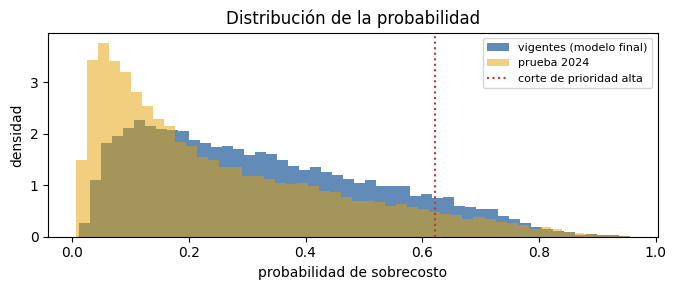

In [117]:
N_TOP = max(1, int(round(CAPACIDAD * len(RANKING))))
top = RANKING.head(N_TOP)
print(f"Prioridad alta: los {N_TOP:,} contratos de mayor probabilidad (el {CAPACIDAD:.0%} de los vigentes) suman "
      f"{top.valor_adjudicado.sum() / 1e9:,.1f} miles de millones de pesos adjudicados "
      f"({top.valor_adjudicado.sum() / RANKING.valor_adjudicado.sum():.1%} del valor de todos los vigentes).")

def reparto(columna, n=10):
    t = pd.DataFrame({"% en prioridad alta": top[columna].value_counts(normalize=True),
                      "% en todos los vigentes": RANKING[columna].value_counts(normalize=True)}).fillna(0)
    t["veces su peso"] = t["% en prioridad alta"] / t["% en todos los vigentes"]
    return t.sort_values("% en prioridad alta", ascending=False).head(n)

REPARTO = {c: reparto(c) for c in ["departamento", "modalidad", "sector", "tipo_de_contrato"]}
for c, t in REPARTO.items():
    print(f"\nPrioridad alta por {c}:")
    display(t.round(3))

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(RANKING.probabilidad, bins=50, color="#3b6ea5", alpha=0.8, density=True, label="vigentes (modelo final)")
ax.hist(MODELOS[CAMPEON]["p_te"], bins=50, color="#e69f00", alpha=0.5, density=True, label=f"prueba {ANIO_PRUEBA}")
ax.axvline(RANKING.probabilidad.iloc[N_TOP - 1], color="#c0392b", ls=":", label="corte de prioridad alta")
ax.set(xlabel="probabilidad de sobrecosto", ylabel="densidad", title="Distribución de la probabilidad")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## 15. Conclusiones

In [118]:
t = tabla.drop(index="Línea base")
d_ref = {n: boot[n]["ap"] - boot[CAMPEON]["ap"] for n in MODELOS if n not in ("Línea base", CAMPEON)}
empatados = [n for n, d in d_ref.items() if np.percentile(d, 2.5) <= 0 <= np.percentile(d, 97.5)]
g10 = TABLA_GANANCIA[(TABLA_GANANCIA.revisar == f"{CAPACIDAD:.0%}") & TABLA_GANANCIA.criterio.str.startswith("campeón")].iloc[0]
print(f"Datos: descarga del {FECHA_DESCARGA.date()} · corrida {DIR_CORRIDA.name}")
print(f"Diseño: entrenamiento {ANIOS_ENTRENAMIENTO} ({len(tr):,} contratos) · prueba {ANIO_PRUEBA} ({len(te):,} contratos) · solo contratos terminados")
print(f"Cobertura: el modelo aplica a modalidades que suman el {COBERTURA:.1%} de los contratos del período (sin la contratación directa ni el régimen especial sin ofertas)")
print(f"Escenario del objetivo: {CORTE_PRINCIPAL} · {len(df):,} contratos · tasa de sobrecosto {df.sobrecosto.mean():.1%} · "
      f"adiciones por {ADICION.sum() / 1e12:,.2f} billones de pesos")
print(f"Campeón (regla automática, sección 10.1): {CAMPEON} · mejor en validación: {MEJOR_CV} · elegibles: {list(elegibles.index)}")
print(f"  PR-AUC CV {AP[CAMPEON].mean():.3f} · prueba: PR-AUC {t.loc[CAMPEON, 'PR-AUC']:.3f}, ROC-AUC {t.loc[CAMPEON, 'ROC-AUC']:.3f} "
      f"(línea base PR-AUC {tabla.loc['Línea base', 'PR-AUC']:.3f})")
print(f"  Revisando el {CAPACIDAD:.0%} de mayor prioridad en 2024: precisión {g10['precisión']:.0%} (tasa {y_te.mean():.0%}), "
      f"{g10['% de los sobrecostos']:.0%} de los sobrecostos y {g10['% de los pesos de sobrecosto']:.0%} de los pesos de sobrecosto")
print(f"Modelos no distinguibles del campeón en PR-AUC de prueba (bootstrap por entidad): {empatados or 'ninguno'}")
print(f"Variables principales del campeón: {TOP_PRINCIPAL}")
print(f"Curva de aprendizaje: del 75 % al 100 % del entrenamiento la PR-AUC cambia {ganancia:+.4f}")
print(f"Robustez al corte del objetivo: {len(comunes)} de 5 variables principales coinciden entre escenarios")
print(f"Segunda ventana temporal ({ventana_2}): PR-AUC del campeón {pr_v2:.3f} frente a {pr_v1:.3f} en la ventana principal; "
      f"{len(comunes_v2)} de 5 variables principales coinciden")
print(f"Priorización: {len(RANKING):,} contratos vigentes {min(ANIOS_PRIORIZAR)}-{max(ANIOS_PRIORIZAR)} sin adiciones de valor; "
      f"prioridad alta = {N_TOP:,} contratos ({top.valor_adjudicado.sum() / 1e9:,.1f} miles de millones adjudicados)")

Datos: descarga del 2026-10-20 · corrida 2026-10-21_1326
Diseño: entrenamiento [2021, 2022, 2023] (176,495 contratos) · prueba 2024 (68,023 contratos) · solo contratos terminados
Cobertura: el modelo aplica a modalidades que suman el 9.5% de los contratos del período (sin la contratación directa ni el régimen especial sin ofertas)
Escenario del objetivo: legal · 244,518 contratos · tasa de sobrecosto 25.5% · adiciones por 19.72 billones de pesos
Campeón (regla automática, sección 10.1): Gradient Boosting · mejor en validación: Gradient Boosting · elegibles: ['Gradient Boosting']
  PR-AUC CV 0.551 · prueba: PR-AUC 0.551, ROC-AUC 0.783 (línea base PR-AUC 0.255)
  Revisando el 10% de mayor prioridad en 2024: precisión 65% (tasa 25%), 25% de los sobrecostos y 65% de los pesos de sobrecosto
Modelos no distinguibles del campeón en PR-AUC de prueba (bootstrap por entidad): ['Bosque aleatorio']
Variables principales del campeón: ['unspsc_familia', 'log_precio_base', 'duracion_dias', 'departame

### Conclusiones del diseño

* La llave entre las dos tablas es `proceso_de_compra` ↔ `id_del_portafolio`, y la variable objetivo es `valor_del_contrato > valor_total_adjudicacion`; la sección 4.3 la contrasta con el conjunto de adiciones.
* Solo entran contratos **terminados**, así que la etiqueta no puede cambiar después de la descarga.
* Se descartan los registros con valor adjudicado incoherente con el precio base (errores de digitación de varios órdenes de magnitud, cerca del 0,5 % de los registros), que distorsionaban los montos y la etiqueta (sección 3).
* El tope legal de adiciones se mide en salarios mínimos, con el año de la última modificación tomado del conjunto de adiciones; un corte fijo de 1,5x en pesos descartaba contratos legales. La sección 12.1 muestra si eso cambia las conclusiones.
* Varias columnas aparentemente inocentes tienen **fuga**: las fuentes de financiación suman el valor final, las fechas de fin se mueven con las prórrogas y algunas cláusulas pueden actualizarse después de firmar (sección 4.4). Incluirlas infla el desempeño (anexo A).
* Todas las decisiones (hiperparámetros, iteraciones, épocas, umbrales y **el campeón**) se toman con validación cruzada **por entidad** dentro de 2021-2023, con una regla fijada de antemano que prefiere el modelo más interpretable cuando la diferencia no es distinguible. La prueba es un **año posterior** (2024), se usa una sola vez para confirmar y sus diferencias se leen con intervalos de bootstrap por entidad.
* El valor práctico se mide como **priorización**: qué parte de los sobrecostos y de sus pesos se encuentra revisando primero lo que señala el modelo (sección 13.2). Con esa lógica, el modelo final ordena los contratos vigentes de 2025-2026 que todavía no tienen adiciones (sección 14).

### Limitaciones

1. **Cobertura: el modelo no aplica a la contratación directa ni al régimen especial sin ofertas.** Esas modalidades no tienen adjudicación ni valor adjudicado en *Procesos* (sección 4.5) y son cerca del 90 % de los contratos del período (`COBERTURA` da la cifra exacta). El precio base no está validado como valor inicial y el conjunto de adiciones no trae montos, así que no hay con qué medir su sobrecosto; además, sus adiciones (sobre todo prórrogas de servicios personales) serían un fenómeno distinto que pediría un modelo aparte. El modelo responde la pregunta para las modalidades competitivas y las variantes «con ofertas».
2. **Sesgo por exigir contratos terminados.** Los contratos que siguen vigentes, muchas veces por prórrogas, quedan fuera, y su tasa parcial de sobrecosto tiende a ser mayor (sección 4.1). El efecto es mayor en 2024, el año de prueba, porque sus contratos han tenido menos tiempo para terminar: la prueba representa mejor a los contratos cortos. Incluir contratos vigentes solo cuando ya tienen sobrecosto no lo corrige: seleccionaría filas según el resultado y sesgaría la tasa hacia arriba.
3. **Solo procesos con un único contrato.** Los procesos con varios lotes quedan fuera porque el valor adjudicado total no se puede repartir entre sus contratos; suelen ser compras más grandes y complejas, y no se sabe si el modelo funciona igual con ellos.
4. **La validación del objetivo es parcial.** El conjunto de adiciones clasifica sus registros de forma irregular y no trae montos: confirma que los contratos sin sobrecosto casi no tienen modificaciones de valor, pero no permite verificar uno por uno el monto de cada adición.
5. **El tope legal es una aproximación.** El año de la última adición se toma del último registro de modificación de valor o general; si el contrato no tiene registros, se usa el año de fin como cota superior. Para el régimen especial, que no tiene tope legal, el umbral de `TOPE_ERROR` es arbitrario.
6. **Dos ventanas temporales, no más, y prácticas de registro que cambian.** La prueba principal es 2024 y la segunda ventana (2023) comparte hiperparámetros elegidos con datos que la incluyen. Las prácticas de registro cambian entre años: la deriva de `liquidaci_n` (sección 4.4) y el aumento de contratos con UNSPSC `UNSPECIFIED` desde 2023 (sección 5.3) son dos ejemplos. Un cambio así podría bajar el desempeño; conviene reevaluar el modelo cada año.
7. **Variables que faltan:** el historial de la entidad y del proveedor (por ejemplo, su tasa de sobrecosto en contratos anteriores), calculado solo con contratos previos a cada firma, y el texto libre del objeto y la descripción, que se dejó fuera porque en parte identifica a la entidad y algunos registros se editan después de firmar (sección 5.1).
8. **Importancia y dependencia parcial no son causalidad**, y variables correlacionadas (precio base y valor adjudicado) se reparten la importancia.
9. **El modelo estima si ocurre un sobrecosto, no su monto.** La priorización usa la probabilidad; el valor adjudicado se muestra para que el usuario lo considere, pero el modelo no estima cuánto crecerá cada contrato. El umbral F-beta de la sección 10.2 es una referencia académica; para operar se revisa un número fijo de contratos según la capacidad (secciones 13.2 y 14).
10. **La regla del campeón es una convención.** Los niveles de interpretabilidad y el margen de un error estándar son decisiones razonables, pero otras reglas (por ejemplo, ignorar la interpretabilidad) podrían elegir otro modelo; la tabla de la sección 10.1 permite ver qué pasaría. Además, el error estándar entre pliegues subestima algo la incertidumbre, porque los pliegues comparten datos de entrenamiento (la corrección de Nadeau y Bengio lo multiplicaría por cerca de 1,5).
11. **Los contratos vigentes no son iguales a los de entrenamiento.** Son más recientes y, en promedio, más largos (los cortos ya terminaron), y su registro puede tener rezagos: una adición todavía no registrada haría que un contrato con sobrecosto aparezca como priorizable. Por eso el ranking se lee como orden de prioridad y no como probabilidad exacta.

**Trabajo futuro:** incorporar el historial de la entidad y del proveedor (solo con contratos anteriores); evaluar el texto libre controlando que no funcione como identificador de la entidad; para la contratación directa, validar si el precio base del proceso sirve como valor inicial; y, como propuesta de operación, **monitorear el modelo**: reentrenarlo cada año, vigilar los cambios en el registro de los datos y comparar el ranking de 2025-2026 con lo que ocurra a medida que esos contratos terminen.

## 16. Exportación de resultados para la página web

Con `EXPORTAR_WEB = True`, se escriben en `docs/datos/` los archivos que lee la página publicada con GitHub Pages: resumen de la corrida, magnitud del problema, curva de ganancia, comparación de modelos, qué impulsa el riesgo, alcance y el ranking de contratos vigentes (los primeros `TOP_WEB` en JSON y la lista completa en CSV). La página no ejecuta Python ni el modelo: solo muestra estos resultados.

In [119]:
def limpiar_json(o):
    if isinstance(o, pd.DataFrame):
        return limpiar_json(o.to_dict("records"))
    if isinstance(o, pd.Series):
        return limpiar_json(o.to_dict())
    if isinstance(o, dict):
        return {str(k): limpiar_json(v) for k, v in o.items()}
    if isinstance(o, (list, tuple, np.ndarray)):
        return [limpiar_json(v) for v in o]
    if isinstance(o, (np.bool_, bool)):
        return bool(o)
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (float, np.floating)):
        return round(float(o), 6) if np.isfinite(o) else None
    if isinstance(o, pd.Timestamp):
        return str(o.date())
    if o is None or o is pd.NA or o is pd.NaT:
        return None
    return o

def a_json(nombre, objeto):
    with open(DIR_WEB / f"{nombre}.json", "w", encoding="utf-8") as f:
        json.dump(limpiar_json(objeto), f, ensure_ascii=False, allow_nan=False)

def muestrear_curva(x, y, n=101):
    i = np.unique(np.linspace(0, len(x) - 1, n).round().astype(int))
    return [{"x": float(x[j]), "y": float(y[j])} for j in i]

if EXPORTAR_WEB:
    DIR_WEB.mkdir(parents=True, exist_ok=True)
    m = MODELOS[CAMPEON]
    a_json("resumen", {
        "titulo": "Priorización de contratos con riesgo de sobrecosto (SECOP II)",
        "fecha_descarga": str(FECHA_DESCARGA.date()), "corrida": DIR_CORRIDA.name,
        "generado": pd.Timestamp.now().strftime("%Y-%m-%d %H:%M"),
        "anios_entrenamiento": ANIOS_ENTRENAMIENTO, "anio_prueba": ANIO_PRUEBA, "anios_priorizar": ANIOS_PRIORIZAR,
        "cobertura": COBERTURA, "embudo": EMBUDO, "tasa_sobrecosto": df.sobrecosto.mean(),
        "campeon": CAMPEON, "mejor_en_validacion": MEJOR_CV, "elegibles": list(elegibles.index),
        "metricas_campeon": {"pr_auc_cv": AP[CAMPEON].mean(), "pr_auc": tabla.loc[CAMPEON, "PR-AUC"],
                             "pr_auc_ic": [np.percentile(boot[CAMPEON]["ap"], 2.5), np.percentile(boot[CAMPEON]["ap"], 97.5)],
                             "roc_auc": tabla.loc[CAMPEON, "ROC-AUC"], "precision_capacidad": tabla.loc[CAMPEON, PK],
                             "capacidad": CAPACIDAD, "tasa_prueba": y_te.mean()},
        "variables_principales": TOP_PRINCIPAL, "n_vigentes": len(RANKING), "n_prioridad_alta": N_TOP,
        "embudo_vigentes": EMBUDO_VIGENTES,
    })
    a_json("magnitud", {"por_anio": MAGNITUD.reset_index(), "concentracion": CONCENTRACION,
                        "total_adiciones": ADICION.sum(), "crecimiento_mediano": crec_pos.median() - 1,
                        "nota": "Pesos corrientes. El modelo estima si ocurre un sobrecosto, no su monto."})
    a_json("ganancia", {"curvas": {n: {"conteo": muestrear_curva(FRAC, g["conteo"]), "pesos": muestrear_curva(FRAC, g["pesos"])}
                                   for n, g in GANANCIA.items()},
                        "tabla": TABLA_GANANCIA, "tasa": y_te.mean(), "anio": ANIO_PRUEBA})
    curvas_pr, calibracion = {}, {}
    for n, mm in MODELOS.items():
        if n == "Línea base":
            continue
        prec, rec, _ = precision_recall_curve(y_te, mm["p_te"])
        orden = np.argsort(rec)
        rejilla = np.linspace(0, 1, 101)
        curvas_pr[n] = [{"x": float(r), "y": float(np.interp(r, rec[orden], prec[orden]))} for r in rejilla]
        frac_c, media_c = calibration_curve(y_te, mm["p_te"], n_bins=10, strategy="quantile")
        calibracion[n] = [{"x": float(a), "y": float(b)} for a, b in zip(media_c, frac_c)]
    a_json("comparacion", {
        "tabla": tabla.reset_index(), "seleccion": seleccion.reset_index(),
        "ic": [{"modelo": n, "pr_auc": np.median(d["ap"]), "pr_auc_inf": np.percentile(d["ap"], 2.5),
                "pr_auc_sup": np.percentile(d["ap"], 97.5), "roc_auc": np.median(d["auc"]),
                "dif_vs_campeon": None if n == CAMPEON else np.median(d["ap"] - boot[CAMPEON]["ap"]),
                "dif_inf": None if n == CAMPEON else np.percentile(d["ap"] - boot[CAMPEON]["ap"], 2.5),
                "dif_sup": None if n == CAMPEON else np.percentile(d["ap"] - boot[CAMPEON]["ap"], 97.5)}
               for n, d in boot.items()],
        "curvas_pr": curvas_pr, "calibracion": calibracion, "por_modalidad": por_modalidad.reset_index(),
        "robustez": robustez.reset_index().rename(columns={"index": "variante"}),
        "curva_aprendizaje": curva.reset_index(), "campeon": CAMPEON,
    })
    a_json("importancia", {"importancia": IMPORTANCIA.sort_values("media", ascending=False).head(15)
                                                    .reset_index().rename(columns={"index": "variable"}),
                           "dependencia": {var: t.assign(valor=t["valor"].astype(str) if var in CATEGORICAS else t["valor"])
                                           for var, t in DEPENDENCIA.items()},
                           "numericas": NUMERICAS})
    a_json("alcance", {"cobertura": COBERTURA, "conteo_modalidades": conteo[["modalidad_de_contratacion", "contratos", "% del total"]],
                       "unspecified_por_anio": SIN_UNSPSC.reset_index().rename(columns={"anio_firma": "anio"}),
                       "clausulas_excluidas": EXCLUIR_POR_DERIVA})
    a_json("ranking_vigentes", {"generado": str(FECHA_DESCARGA.date()), "total": len(RANKING),
                                "publicados": min(TOP_WEB, len(RANKING)), "prioridad_alta": N_TOP,
                                "reparto_prioridad_alta": {c: t.reset_index().rename(columns={"index": c, c: c})
                                                           for c, t in REPARTO.items()},
                                "filas": RANKING.head(TOP_WEB)})
    RANKING.to_csv(DIR_WEB / "ranking_vigentes.csv", index=False, encoding="utf-8-sig")
    tam = {p.name: f"{p.stat().st_size / 1e6:.2f} MB" for p in sorted(DIR_WEB.glob("*"))}
    print(f"Exportado a {DIR_WEB.resolve()}:")
    display(pd.Series(tam, name="tamaño").to_frame())
else:
    print("EXPORTAR_WEB = False: no se escribió nada en docs/datos/")

Exportado a G:\My Drive\Carpeta_raiz\EAN\Semestre1\Machine_Learning\Proyecto_Final\docs\datos:


,tamaño
alcance.json,0.00 MB
comparacion.json,0.02 MB
ganancia.json,0.02 MB
importancia.json,0.01 MB
magnitud.json,0.00 MB
ranking_vigentes.csv,17.08 MB
ranking_vigentes.json,4.32 MB
resumen.json,0.00 MB


## Anexo A. ¿Cuánto infla la fuga de información las métricas? (capítulo académico)

Se usa el Gradient Boosting (sea o no el campeón), con la misma partición, agregando columnas con fuga: el efecto se ve igual en cualquier modelo flexible. Estas cifras **no son válidas**: se muestran para justificar la exclusión de las columnas de la sección 5.1. Al cargar una corrida se muestran los resultados guardados.

In [120]:
def evaluar(nombre, p, umbral):
    return {"modelo": nombre, "ROC-AUC": roc_auc_score(y_te, p),
            "PR-AUC": average_precision_score(y_te, p), "F1": f1_score(y_te, p >= umbral)}

def con_extras(extras):
    A, B = Xc_tr.copy(), Xc_te.copy()
    for nombre, serie in extras.items():
        A[nombre], B[nombre] = serie.iloc[tr].values, serie.iloc[te].values
    mod = HistGradientBoostingClassifier(max_iter=mejor["iters"], max_leaf_nodes=mejor["hojas"], **gb_base).fit(A, y_tr)
    return mod.predict_proba(B)[:, 1]

if ENTRENAR_MODELOS:
    u_gb = MODELOS["Gradient Boosting"]["umbral"]
    fuga = {
        "estado_contrato": df.estado_contrato.astype("category"),
        "dias_adicionados": num(df.dias_adicionados),
        "fuente_pgn": num(df.presupuesto_general_de_la_nacion_pgn),
        "fuente_recursos_propios": num(df.recursos_propios),
        "duracion_por_fechas": dur_fechas,
    }
    comparacion = pd.DataFrame([
        evaluar("Limpio (al adjudicar)", p_gb, u_gb),
        evaluar("+ fuga (estado, días adicionados, fuentes, fechas)", con_extras(fuga), u_gb),
        evaluar("+ fuga total (valor_del_contrato)", con_extras({**fuga, "log_valor_final": np.log1p(df.valor_final)}), u_gb),
    ]).set_index("modelo").round(3)
    RESULTADOS["fuga"] = comparacion
    guardar_resultados()
else:
    comparacion = RESULTADOS["fuga"]
comparacion

,ROC-AUC,PR-AUC,F1
modelo,,,
Limpio (al adjudicar),0.783,0.551,0.555
"+ fuga (estado, días adicionados, fuentes, fechas)",0.929,0.839,0.732
+ fuga total (valor_del_contrato),0.993,0.986,0.938
